## Verficiation du disponibilte du GPU

In [1]:
import torch
import os

# Vérifier GPU
print(f"GPU dispo : {torch.cuda.is_available()}")
print(f"GPU nom   : {torch.cuda.get_device_name(0)}")
print(f"Nombre GPU: {torch.cuda.device_count()}")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device    : {device}")

# Vérifier le dataset
print("\n=== Contenu kaggle/input ===")
print(os.listdir("/kaggle/input/"))

GPU dispo : True
GPU nom   : Tesla T4
Nombre GPU: 2
Device    : cuda

=== Contenu kaggle/input ===
['datasets']


## Exploration du dataset

In [2]:


# Explorer le dossier datasets
print(os.listdir("/kaggle/input/datasets"))

# Explorer plus profond
for root, dirs, files in os.walk("/kaggle/input/"):
    level = root.replace("/kaggle/input/", "").count(os.sep)
    indent = " " * 2 * level
    print(f"{indent}{os.path.basename(root)}/")
    if level < 3:  # affiche seulement 3 niveaux
        subindent = " " * 2 * (level + 1)
        # Affiche max 5 fichiers par dossier
        for f in list(files)[:5]:
            print(f"{subindent}{f}")

['adityajn105']
/
datasets/
  adityajn105/
    flickr30k/
      captions.txt
      Images/
        flickr30k_images/


In [3]:
import pandas as pd


# Chemins
BASE_DIR = "/kaggle/input/datasets/adityajn105/flickr30k"
CSV_PATH = f"{BASE_DIR}/captions.txt"
IMG_DIR  = f"{BASE_DIR}/Images/flickr30k_images"

# Vérifier les images
images = os.listdir(IMG_DIR)
print(f"Nombre d'images : {len(images)}")
print(f"Exemple         : {images[:3]}")

# Vérifier le CSV
with open(CSV_PATH, "r", encoding="utf-8") as f:
    for i, line in enumerate(f):
        print(repr(line))
        if i > 4:
            break

Nombre d'images : 31783
Exemple         : ['2715746315.jpg', '3463034205.jpg', '268704620.jpg']
'image,caption\n'
'1000092795.jpg, Two young guys with shaggy hair look at their hands while hanging out in the yard .\n'
'1000092795.jpg," Two young , White males are outside near many bushes ."\n'
'1000092795.jpg, Two men in green shirts are standing in a yard .\n'
'1000092795.jpg, A man in a blue shirt standing in a garden .\n'
'1000092795.jpg, Two friends enjoy time spent together .\n'


## Etape 1: Text and Data Preprocessing for Training

In [3]:
import pandas as pd
import os
import re
from collections import Counter
from sklearn.model_selection import train_test_split
import pickle
import torch

# ============ CHEMINS ============
BASE_DIR = "/kaggle/input/datasets/adityajn105/flickr30k"
CSV_PATH = f"{BASE_DIR}/captions.txt"
IMG_DIR  = f"{BASE_DIR}/Images/flickr30k_images"

# ============ CHARGEMENT ============
df = pd.read_csv(CSV_PATH)
df.columns = df.columns.str.strip()#enlève les espaces dans les noms de colonnes
print(f"Colonnes : {df.columns.tolist()}")
print(f"Shape    : {df.shape}")
print(df.head(5))

# ============ NETTOYAGE ============
df = df.dropna(subset=["caption"])
df["image"]   = df["image"].str.strip()#enlève espaces inutiles
df["caption"] = df["caption"].str.strip()

def clean_caption(text):
    text = text.lower()#tout en minuscules
    text = re.sub(r"[^a-z0-9\s]", "", text)# supprime :caractères spéciaux et ponctuation
    text = re.sub(r"\s+", " ", text).strip()#enlève espaces multiples
    return text

df["caption"] = df["caption"].apply(clean_caption)
print(f"\nAprès nettoyage : {df.shape}")
print(df.head(5))

# ============ VOCABULAIRE ============
#découpes toutes les phrases en mots
all_words = []
for caption in df["caption"]:
    all_words.extend(caption.split())

#compter fréquence
word_counts = Counter(all_words)
print(f"\nMots uniques totaux : {len(word_counts)}")

#minimum 5 fois exite 
MIN_FREQ = 5
vocab_words = [word for word, count in word_counts.items() if count >= MIN_FREQ]
special_tokens = ["<PAD>", "<START>", "<END>", "<UNK>"]
vocab = special_tokens + sorted(vocab_words)

word2idx = {word: idx for idx, word in enumerate(vocab)}#chaque mot reçoit un id
idx2word = {idx: word for word, idx in word2idx.items()}#numéro → mot

print(f"Vocabulaire final   : {len(vocab)} mots")

# ============ SPLIT ============
all_images = df["image"].unique().tolist()
train_imgs, temp_imgs = train_test_split(all_images, test_size=0.2, random_state=42)#80 train 20temp
val_imgs, test_imgs   = train_test_split(temp_imgs,  test_size=0.5, random_state=42)#10 test 10 validation

train_df = df[df["image"].isin(train_imgs)].reset_index(drop=True)
val_df   = df[df["image"].isin(val_imgs)].reset_index(drop=True)
test_df  = df[df["image"].isin(test_imgs)].reset_index(drop=True)

print(f"\nTrain : {train_df['image'].nunique()} images / {len(train_df)} captions")
print(f"Val   : {val_df['image'].nunique()} images / {len(val_df)} captions")
print(f"Test  : {test_df['image'].nunique()} images / {len(test_df)} captions")

# ============ SAUVEGARDE ============
data_to_save = {
    "word2idx": word2idx,
    "idx2word": idx2word,
    "vocab_size": len(vocab),
    "train_df": train_df,
    "val_df": val_df,
    "test_df": test_df,
}
with open("preprocessing.pkl", "wb") as f:
    pickle.dump(data_to_save, f)

print("\n✅ Preprocessing sauvegardé !")

Colonnes : ['image', 'caption']
Shape    : (158915, 2)
            image                                            caption
0  1000092795.jpg   Two young guys with shaggy hair look at their...
1  1000092795.jpg   Two young , White males are outside near many...
2  1000092795.jpg   Two men in green shirts are standing in a yard .
3  1000092795.jpg       A man in a blue shirt standing in a garden .
4  1000092795.jpg            Two friends enjoy time spent together .

Après nettoyage : (158914, 2)
            image                                            caption
0  1000092795.jpg  two young guys with shaggy hair look at their ...
1  1000092795.jpg  two young white males are outside near many bu...
2  1000092795.jpg     two men in green shirts are standing in a yard
3  1000092795.jpg         a man in a blue shirt standing in a garden
4  1000092795.jpg              two friends enjoy time spent together

Mots uniques totaux : 20007
Vocabulaire final   : 7727 mots

Train : 25426 images / 1

## Étape 2 — Dataset Class + DataLoader


In [5]:
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torchvision.transforms as transforms

class Flickr30kDataset(Dataset):
    def __init__(self, df, img_dir, word2idx, max_len=50, transform=None):
        self.df        = df
        self.img_dir   = img_dir
        self.word2idx  = word2idx
        self.max_len   = max_len
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def encode_caption(self, caption):#transforme une phrase en nombres
        tokens  = caption.split()
        encoded = [self.word2idx["<START>"]]
        for word in tokens:
            encoded.append(self.word2idx.get(word, self.word2idx["<UNK>"]))
        encoded.append(self.word2idx["<END>"])
        length = len(encoded)
        if len(encoded) < self.max_len:
            encoded += [self.word2idx["<PAD>"]] * (self.max_len - len(encoded))
        else:
            encoded = encoded[:self.max_len]
        return encoded, min(length, self.max_len)

    def __getitem__(self, idx):
        row        = self.df.iloc[idx]
        img_path   = os.path.join(self.img_dir, row["image"])
        image      = Image.open(img_path).convert("RGB")
        if self.transform:
            image  = self.transform(image)
        encoded, length = self.encode_caption(row["caption"])
        return image, torch.tensor(encoded, dtype=torch.long), length

# ============ TRANSFORMATIONS ============
transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# ============ DATASETS ============
train_dataset = Flickr30kDataset(train_df, IMG_DIR, word2idx, transform=transform)
val_dataset   = Flickr30kDataset(val_df,   IMG_DIR, word2idx, transform=transform)
test_dataset  = Flickr30kDataset(test_df,  IMG_DIR, word2idx, transform=transform)

# ============ DATALOADERS ============
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=32, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

# ============ TEST ============
images, captions, lengths = next(iter(train_loader))
print(f"Batch images shape   : {images.shape}")
print(f"Batch captions shape : {captions.shape}")
print(f"Batch lengths        : {lengths}")
print(f"\n✅ DataLoaders prêts !")

Batch images shape   : torch.Size([32, 3, 224, 224])
Batch captions shape : torch.Size([32, 50])
Batch lengths        : tensor([20, 13, 10, 12, 12, 22, 32, 17, 28, 14, 11, 12, 18, 17, 12, 11, 12, 15,
        16, 24, 19, 18, 14, 12, 22,  8, 12, 12, 11, 20, 19, 12])

✅ DataLoaders prêts !


## Étape 3 — Encoder CNN 🚀

In [6]:
import torch
import torch.nn as nn
import torchvision.models as models

class Encoder(nn.Module):
    def __init__(self, encoded_image_size=14):
        super(Encoder, self).__init__()
        self.enc_image_size = encoded_image_size

        # ResNet101 pré-entraîné
        resnet = models.resnet101(weights="IMAGENET1K_V1")

        # Supprimer les 2 dernières couches (avgpool + fc)
        modules = list(resnet.children())[:-2]
        self.resnet = nn.Sequential(*modules)

        # Adapter la taille de sortie à 14x14
        self.adaptive_pool = nn.AdaptiveAvgPool2d((encoded_image_size, encoded_image_size))

        # Geler les couches du ResNet (on ne réentraîne pas le CNN)
        self.fine_tune(fine_tune=False)

    def forward(self, images):
        # images : [batch, 3, 224, 224]
        features = self.resnet(images)             # [batch, 2048, 7, 7]
        features = self.adaptive_pool(features)    # [batch, 2048, 14, 14]
        features = features.permute(0, 2, 3, 1)   # [batch, 14, 14, 2048]
        return features

    def fine_tune(self, fine_tune=True):
        # Geler ou dégeler les couches
        for p in self.resnet.parameters():
            p.requires_grad = False
        # Dégeler seulement les 2 derniers blocs si fine_tune=True
        if fine_tune:
            for c in list(self.resnet.children())[5:]:
                for p in c.parameters():
                    p.requires_grad = True

# ============ TEST ============
device  = torch.device("cuda" if torch.cuda.is_available() else "cpu")
encoder = Encoder(encoded_image_size=14).to(device)

# Tester avec un batch
images, captions, lengths = next(iter(train_loader))
images = images.to(device)

with torch.no_grad():
    features = encoder(images)

print(f"Input  shape : {images.shape}")
print(f"Output shape : {features.shape}")
print(f"\n✅ Encoder prêt !")
print(f"Chaque image → {features.shape[1]}×{features.shape[2]} locations × {features.shape[3]} features")

Downloading: "https://download.pytorch.org/models/resnet101-63fe2227.pth" to /root/.cache/torch/hub/checkpoints/resnet101-63fe2227.pth


100%|██████████| 171M/171M [00:00<00:00, 206MB/s] 


Input  shape : torch.Size([32, 3, 224, 224])
Output shape : torch.Size([32, 14, 14, 2048])

✅ Encoder prêt !
Chaque image → 14×14 locations × 2048 features


## Étape 4 — Soft Attention + Decoder LSTM

In [7]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# ============================================
# SOFT ATTENTION
# ============================================
class SoftAttention(nn.Module):
    def __init__(self, encoder_dim, decoder_dim, attention_dim):
        """
        encoder_dim  : taille des features CNN (2048)
        decoder_dim  : taille du hidden state LSTM (512)
        attention_dim: taille de la couche attention (512)
        """
        super(SoftAttention, self).__init__()

        # Projette les features CNN vers attention_dim
        self.encoder_att = nn.Linear(encoder_dim, attention_dim)
        # Projette le hidden state LSTM vers attention_dim
        self.decoder_att = nn.Linear(decoder_dim, attention_dim)
        # Calcule le score final (1 valeur par location)
        self.full_att = nn.Linear(attention_dim, 1)
        self.relu     = nn.ReLU()
        self.softmax  = nn.Softmax(dim=1)

    def forward(self, encoder_out, decoder_hidden):
        """
        encoder_out    : [batch, 196, 2048]
        decoder_hidden : [batch, 512]
        """
        # Projections
        att1 = self.encoder_att(encoder_out)      # [batch, 196, attention_dim]
        att2 = self.decoder_att(decoder_hidden)    # [batch, attention_dim]

        # Addition et score
        att  = self.full_att(self.relu(att1 + att2.unsqueeze(1))).squeeze(2)  # [batch, 196]

        # Poids alpha avec softmax
        alpha = self.softmax(att)                  # [batch, 196]

        # Contexte = somme pondérée des features
        context = (encoder_out * alpha.unsqueeze(2)).sum(dim=1)  # [batch, 2048]

        return context, alpha


# ============================================
# DECODER LSTM
# ============================================
class DecoderWithSoftAttention(nn.Module):
    def __init__(self, attention_dim, embed_dim, decoder_dim,
                 vocab_size, encoder_dim=2048, dropout=0.5):
        """
        attention_dim : taille couche attention (512)
        embed_dim     : taille embedding mots (512)
        decoder_dim   : taille hidden state LSTM (512)
        vocab_size    : taille vocabulaire (7727)
        encoder_dim   : taille features CNN (2048)
        dropout       : dropout (0.5)
        """
        super(DecoderWithSoftAttention, self).__init__()

        self.attention_dim = attention_dim
        self.embed_dim     = embed_dim
        self.decoder_dim   = decoder_dim
        self.vocab_size    = vocab_size
        self.encoder_dim   = encoder_dim

        # Couches
        self.attention  = SoftAttention(encoder_dim, decoder_dim, attention_dim)
        self.embedding  = nn.Embedding(vocab_size, embed_dim)
        self.dropout    = nn.Dropout(p=dropout)
        self.lstm_cell  = nn.LSTMCell(embed_dim + encoder_dim, decoder_dim)
        self.fc         = nn.Linear(decoder_dim, vocab_size)

        # Init hidden state et cell state depuis les features CNN
        self.init_h = nn.Linear(encoder_dim, decoder_dim)
        self.init_c = nn.Linear(encoder_dim, decoder_dim)

        self._init_weights()

    def _init_weights(self):
        # Initialisation des poids
        self.embedding.weight.data.uniform_(-0.1, 0.1)
        self.fc.bias.data.fill_(0)
        self.fc.weight.data.uniform_(-0.1, 0.1)

    def init_hidden_state(self, encoder_out):
        """
        Initialise h et c depuis la moyenne des features CNN
        encoder_out : [batch, 196, 2048]
        """
        mean_encoder_out = encoder_out.mean(dim=1)        # [batch, 2048]
        h = torch.tanh(self.init_h(mean_encoder_out))     # [batch, decoder_dim]
        c = torch.tanh(self.init_c(mean_encoder_out))     # [batch, decoder_dim]
        return h, c

    def forward(self, encoder_out, captions, lengths):
        """
        encoder_out : [batch, 14, 14, 2048]
        captions    : [batch, max_len]
        lengths     : [batch]
        """
        batch_size    = encoder_out.shape[0]
        encoder_dim   = encoder_out.shape[-1]
        vocab_size    = self.vocab_size

        # Aplatir les features : [batch, 196, 2048]
        encoder_out = encoder_out.view(batch_size, -1, encoder_dim)
        num_pixels  = encoder_out.shape[1]

        # Trier par longueur décroissante
        lengths, sort_idx = lengths.sort(dim=0, descending=True)
        encoder_out       = encoder_out[sort_idx]
        captions          = captions[sort_idx]

        # Embeddings des mots
        embeddings = self.embedding(captions)              # [batch, max_len, embed_dim]

        # Init hidden state
        h, c = self.init_hidden_state(encoder_out)        # [batch, decoder_dim]

        # On génère jusqu'à max_len - 1 (sans le <END>)
        decode_lengths = (lengths - 1).tolist()
        max_decode_len = max(decode_lengths)

        # Tenseurs pour stocker les prédictions et alphas
        predictions = torch.zeros(batch_size, max_decode_len, vocab_size).to(encoder_out.device)
        alphas      = torch.zeros(batch_size, max_decode_len, num_pixels).to(encoder_out.device)

        # Boucle sur chaque pas de temps
        for t in range(max_decode_len):
            # Nombre de séquences encore actives à ce pas
            batch_size_t = sum([l > t for l in decode_lengths])

            # Attention
            context, alpha = self.attention(
                encoder_out[:batch_size_t],
                h[:batch_size_t]
            )                                              # [batch_t, 2048], [batch_t, 196]

            # LSTM step
            lstm_input = torch.cat(
                [embeddings[:batch_size_t, t, :], context], dim=1
            )                                              # [batch_t, embed_dim + 2048]

            h, c = self.lstm_cell(
                lstm_input,
                (h[:batch_size_t], c[:batch_size_t])
            )                                              # [batch_t, decoder_dim]

            # Prédiction du mot
            preds = self.fc(self.dropout(h))              # [batch_t, vocab_size]

            predictions[:batch_size_t, t, :] = preds
            alphas[:batch_size_t, t, :]      = alpha

        return predictions, captions, decode_lengths, alphas, sort_idx


# ============================================
# TEST
# ============================================
ENCODER_DIM   = 2048
ATTENTION_DIM = 512
EMBED_DIM     = 512
DECODER_DIM   = 512
VOCAB_SIZE    = len(word2idx)  # 7727
DROPOUT       = 0.5

decoder = DecoderWithSoftAttention(
    attention_dim = ATTENTION_DIM,
    embed_dim     = EMBED_DIM,
    decoder_dim   = DECODER_DIM,
    vocab_size    = VOCAB_SIZE,
    encoder_dim   = ENCODER_DIM,
    dropout       = DROPOUT
).to(device)

# Test avec un batch
images, captions, lengths = next(iter(train_loader))
images   = images.to(device)
captions = captions.to(device)
lengths  = lengths.to(device)

with torch.no_grad():
    features                                    = encoder(images)
    predictions, caps_sorted, decode_lengths, alphas, sort_idx = decoder(features, captions, lengths)

print(f"Features shape     : {features.shape}")
print(f"Predictions shape  : {predictions.shape}")
print(f"Alphas shape       : {alphas.shape}")
print(f"\n✅ Soft Attention + Decoder prêts !")

Features shape     : torch.Size([32, 14, 14, 2048])
Predictions shape  : torch.Size([32, 26, 7727])
Alphas shape       : torch.Size([32, 26, 196])

✅ Soft Attention + Decoder prêts !


## Étape 5 — Entraînement Soft Attention 🚀

In [8]:
import torch.optim as optim
from torch.nn.utils.rnn import pack_padded_sequence
import time

# ============================================
# HYPERPARAMETRES
# ============================================
EPOCHS        = 10
LEARNING_RATE = 4e-4
GRAD_CLIP     = 5.0
ALPHA_C       = 1.0
PRINT_EVERY   = 100

# ============================================
# OPTIMISEUR (seulement decoder au début)
# ============================================
decoder_optimizer = optim.Adam(decoder.parameters(), lr=LEARNING_RATE)
encoder_optimizer = None  # sera créé après epoch 5

# ============================================
# LOSS
# ============================================
criterion = nn.CrossEntropyLoss(ignore_index=word2idx["<PAD>"]).to(device)

# ============================================
# FONCTION TRAIN
# ============================================
def train_one_epoch(encoder, decoder, train_loader,
                    encoder_optimizer, decoder_optimizer,
                    criterion, epoch):
    encoder.train()
    decoder.train()

    total_loss = 0
    start_time = time.time()

    for i, (images, captions, lengths) in enumerate(train_loader):
        images   = images.to(device)
        captions = captions.to(device)
        lengths  = lengths.to(device)

        # Forward
        features = encoder(images)
        predictions, caps_sorted, decode_lengths, alphas, sort_idx = decoder(
            features, captions, lengths
        )

        # Targets sans <START>
        targets = caps_sorted[:, 1:]

        # Pack
        predictions_packed = pack_padded_sequence(
            predictions, decode_lengths, batch_first=True
        ).data
        targets_packed = pack_padded_sequence(
            targets, decode_lengths, batch_first=True
        ).data

        # Loss
        loss  = criterion(predictions_packed, targets_packed)
        loss += ALPHA_C * ((1.0 - alphas.sum(dim=1)) ** 2).mean()

        # Backward
        decoder_optimizer.zero_grad()
        if encoder_optimizer is not None:
            encoder_optimizer.zero_grad()

        loss.backward()

        torch.nn.utils.clip_grad_norm_(decoder.parameters(), GRAD_CLIP)
        if encoder_optimizer is not None:
            torch.nn.utils.clip_grad_norm_(encoder.parameters(), GRAD_CLIP)

        decoder_optimizer.step()
        if encoder_optimizer is not None:
            encoder_optimizer.step()

        total_loss += loss.item()

        if (i + 1) % PRINT_EVERY == 0:
            avg_loss = total_loss / (i + 1)
            elapsed  = time.time() - start_time
            print(f"Epoch [{epoch+1}/{EPOCHS}] "
                  f"Step [{i+1}/{len(train_loader)}] "
                  f"Loss: {avg_loss:.4f} "
                  f"Time: {elapsed:.1f}s")

    return total_loss / len(train_loader)

# ============================================
# FONCTION VALIDATE
# ============================================
def validate(encoder, decoder, val_loader, criterion):
    encoder.eval()
    decoder.eval()

    total_loss = 0

    with torch.no_grad():
        for images, captions, lengths in val_loader:
            images   = images.to(device)
            captions = captions.to(device)
            lengths  = lengths.to(device)

            features = encoder(images)
            predictions, caps_sorted, decode_lengths, alphas, sort_idx = decoder(
                features, captions, lengths
            )

            targets = caps_sorted[:, 1:]

            predictions_packed = pack_padded_sequence(
                predictions, decode_lengths, batch_first=True
            ).data
            targets_packed = pack_padded_sequence(
                targets, decode_lengths, batch_first=True
            ).data

            loss  = criterion(predictions_packed, targets_packed)
            loss += ALPHA_C * ((1.0 - alphas.sum(dim=1)) ** 2).mean()

            total_loss += loss.item()

    return total_loss / len(val_loader)

# ============================================
# BOUCLE PRINCIPALE
# ============================================
best_val_loss = float("inf")
train_losses  = []
val_losses    = []

print("🚀 Début de l'entraînement Soft Attention !\n")

for epoch in range(EPOCHS):

    train_loss = train_one_epoch(
        encoder, decoder, train_loader,
        encoder_optimizer, decoder_optimizer,
        criterion, epoch
    )

    val_loss = validate(encoder, decoder, val_loader, criterion)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(f"\n{'='*60}")
    print(f"Epoch {epoch+1}/{EPOCHS} terminée")
    print(f"Train Loss : {train_loss:.4f}")
    print(f"Val Loss   : {val_loss:.4f}")

    # Sauvegarder le meilleur modèle
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save({
            "epoch"              : epoch + 1,
            "encoder_state_dict" : encoder.state_dict(),
            "decoder_state_dict" : decoder.state_dict(),
            "decoder_optimizer"  : decoder_optimizer.state_dict(),
            "val_loss"           : val_loss,
            "word2idx"           : word2idx,
            "idx2word"           : idx2word,
        }, "best_soft_attention.pth")
        print(f"✅ Meilleur modèle sauvegardé ! Val Loss: {val_loss:.4f}")

    # Fine-tune CNN après epoch 5
    if epoch == 4:
        print("\n🔓 Fine-tuning du CNN activé !")
        encoder.fine_tune(fine_tune=True)
        encoder_optimizer = optim.Adam(
            filter(lambda p: p.requires_grad, encoder.parameters()),
            lr=1e-5
        )

    print(f"{'='*60}\n")

print("🎉 Entraînement terminé !")
print(f"Meilleure Val Loss : {best_val_loss:.4f}")

🚀 Début de l'entraînement Soft Attention !

Epoch [1/10] Step [100/3973] Loss: 6.8319 Time: 35.9s
Epoch [1/10] Step [200/3973] Loss: 6.4375 Time: 71.8s
Epoch [1/10] Step [300/3973] Loss: 6.1926 Time: 107.8s
Epoch [1/10] Step [400/3973] Loss: 6.0220 Time: 143.8s
Epoch [1/10] Step [500/3973] Loss: 5.8875 Time: 180.2s
Epoch [1/10] Step [600/3973] Loss: 5.7933 Time: 216.2s
Epoch [1/10] Step [700/3973] Loss: 5.7063 Time: 251.9s
Epoch [1/10] Step [800/3973] Loss: 5.6372 Time: 287.9s
Epoch [1/10] Step [900/3973] Loss: 5.5772 Time: 323.5s
Epoch [1/10] Step [1000/3973] Loss: 5.5195 Time: 359.1s
Epoch [1/10] Step [1100/3973] Loss: 5.4725 Time: 395.0s
Epoch [1/10] Step [1200/3973] Loss: 5.4290 Time: 430.8s
Epoch [1/10] Step [1300/3973] Loss: 5.3924 Time: 466.6s
Epoch [1/10] Step [1400/3973] Loss: 5.3572 Time: 502.3s
Epoch [1/10] Step [1500/3973] Loss: 5.3221 Time: 538.2s
Epoch [1/10] Step [1600/3973] Loss: 5.2897 Time: 573.9s
Epoch [1/10] Step [1700/3973] Loss: 5.2602 Time: 609.5s
Epoch [1/10] St

##  l'Étape 6 — Évaluation BLEU 🚀

In [17]:
import nltk
nltk.download('punkt')
nltk.download('wordnet')
nltk.download('omw-1.4')
from nltk.translate.bleu_score import corpus_bleu
from nltk.translate.meteor_score import meteor_score

# Charger les poids dans encoder et decoder
encoder.load_state_dict(checkpoint["encoder_state_dict"])
decoder.load_state_dict(checkpoint["decoder_state_dict"])
encoder.eval()
decoder.eval()
print("✅ Poids chargés !")

# Générer captions
def generate_caption(encoder, decoder, image, word2idx, idx2word, max_len=50):
    encoder.eval()
    decoder.eval()
    with torch.no_grad():
        image       = image.unsqueeze(0).to(device)
        features    = encoder(image)
        batch_size  = features.shape[0]
        encoder_dim = features.shape[-1]
        features    = features.view(batch_size, -1, encoder_dim)
        h, c        = decoder.init_hidden_state(features)
        word        = torch.tensor([word2idx["<START>"]]).to(device)
        caption     = []
        alphas      = []
        for _ in range(max_len):
            emb            = decoder.embedding(word)
            context, alpha = decoder.attention(features, h)
            lstm_input     = torch.cat([emb, context], dim=1)
            h, c           = decoder.lstm_cell(lstm_input, (h, c))
            output         = decoder.fc(h)
            word           = output.argmax(dim=1)
            word_str       = idx2word[word.item()]
            if word_str == "<END>":
                break
            if word_str not in ["<PAD>", "<START>", "<UNK>"]:
                caption.append(word_str)
            alphas.append(alpha.squeeze(0).cpu())
    return caption, alphas

# Calculer BLEU + METEOR
references_soft = []
hypotheses_soft = []

print("Calcul BLEU + METEOR Soft Attention...")
test_groups = test_df.groupby("image")["caption"].apply(list).reset_index()

for idx, row in test_groups.iterrows():
    img_path = os.path.join(IMG_DIR, row["image"])
    try:
        image = Image.open(img_path).convert("RGB")
        image = transform(image)
    except:
        continue
    generated, _ = generate_caption(encoder, decoder, image, word2idx, idx2word)
    refs          = [clean_caption(cap).split() for cap in row["caption"]]
    references_soft.append(refs)
    hypotheses_soft.append(generated)
    if (idx + 1) % 500 == 0:
        print(f"  {idx+1}/{len(test_groups)} images traitées...")

# BLEU
bleu1_soft = corpus_bleu(references_soft, hypotheses_soft, weights=(1, 0, 0, 0))
bleu2_soft = corpus_bleu(references_soft, hypotheses_soft, weights=(0.5, 0.5, 0, 0))
bleu3_soft = corpus_bleu(references_soft, hypotheses_soft, weights=(0.33, 0.33, 0.33, 0))
bleu4_soft = corpus_bleu(references_soft, hypotheses_soft, weights=(0.25, 0.25, 0.25, 0.25))

# METEOR - version corrigée
meteor_scores_soft = []
for refs, hyp in zip(references_soft, hypotheses_soft):
    # refs est déjà une liste de listes de mots ✅
    # hyp est déjà une liste de mots ✅
    # On passe directement sans convertir en string
    score = meteor_score(refs, hyp)
    meteor_scores_soft.append(score)

meteor_soft = sum(meteor_scores_soft) / len(meteor_scores_soft) * 100

print(f"\n=== Scores Soft Attention ===")
print(f"BLEU-1 : {bleu1_soft*100:.2f}")
print(f"BLEU-2 : {bleu2_soft*100:.2f}")
print(f"BLEU-3 : {bleu3_soft*100:.2f}")
print(f"BLEU-4 : {bleu4_soft*100:.2f}")
print(f"METEOR : {meteor_soft:.2f}")

[nltk_data] Downloading package punkt to /usr/share/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package wordnet to /usr/share/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /usr/share/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


✅ Poids chargés !
Calcul BLEU + METEOR Soft Attention...
  500/3179 images traitées...
  1000/3179 images traitées...
  1500/3179 images traitées...
  2000/3179 images traitées...
  2500/3179 images traitées...
  3000/3179 images traitées...

=== Scores Soft Attention ===
BLEU-1 : 61.97
BLEU-2 : 43.89
BLEU-3 : 30.82
BLEU-4 : 21.41
METEOR : 38.79



Image : 1003163366.jpg
Caption générée : a dog is sleeping on a bench


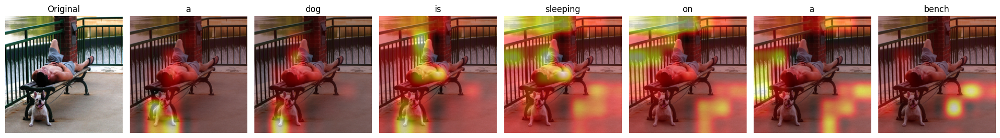

✅ Sauvegardé : attention_soft.png

Image : 101093029.jpg
Caption générée : a woman in a black dress is walking down the street


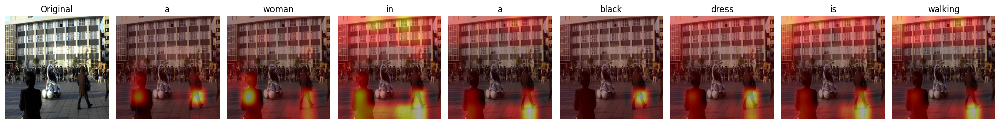

✅ Sauvegardé : attention_soft.png

Image : 101362650.jpg
Caption générée : a woman in a white shirt is sitting on a red mat


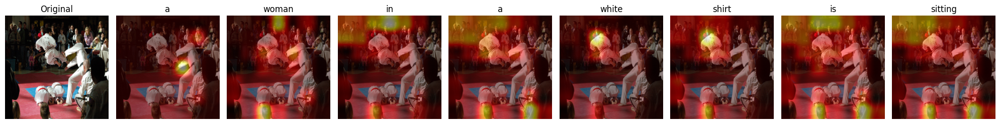

✅ Sauvegardé : attention_soft.png


In [18]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np

def visualize_attention(image_path, encoder, decoder, word2idx, idx2word):
    # Charger image originale
    raw_image = Image.open(image_path).convert("RGB")
    image_tensor = transform(raw_image)

    # Générer caption
    caption, alphas = generate_caption(
        encoder, decoder, image_tensor, word2idx, idx2word
    )

    print(f"Caption générée : {' '.join(caption)}")

    # Afficher image + attention
    fig, axes = plt.subplots(1, min(len(caption), 8) + 1,
                              figsize=(20, 4))

    # Image originale
    axes[0].imshow(raw_image.resize((224, 224)))
    axes[0].set_title("Original")
    axes[0].axis("off")

    # Attention pour chaque mot
    for i, (word, alpha) in enumerate(zip(caption[:8], alphas[:8])):
        alpha_np = alpha.numpy().reshape(14, 14)
        alpha_np = np.array(Image.fromarray(alpha_np).resize(
            (224, 224), Image.LANCZOS)
        )

        axes[i+1].imshow(raw_image.resize((224, 224)))
        axes[i+1].imshow(alpha_np, alpha=0.5, cmap="hot")
        axes[i+1].set_title(word)
        axes[i+1].axis("off")

    plt.tight_layout()
    plt.savefig("attention_soft.png", dpi=100, bbox_inches="tight")
    plt.show()
    print("✅ Sauvegardé : attention_soft.png")

# Tester sur quelques images
test_images = test_df["image"].unique()[:3]
for img_name in test_images:
    img_path = os.path.join(IMG_DIR, img_name)
    print(f"\nImage : {img_name}")
    visualize_attention(img_path, encoder, decoder, word2idx, idx2word)

## Étape 7 — Hard Attention

In [19]:
# ============================================
# HARD ATTENTION
# ============================================
class HardAttention(nn.Module):
    def __init__(self, encoder_dim, decoder_dim, attention_dim):
        super(HardAttention, self).__init__()

        self.encoder_att = nn.Linear(encoder_dim, attention_dim)
        self.decoder_att = nn.Linear(decoder_dim, attention_dim)
        self.full_att    = nn.Linear(attention_dim, 1)
        self.relu        = nn.ReLU()
        self.softmax     = nn.Softmax(dim=1)

    def forward(self, encoder_out, decoder_hidden):
        """
        encoder_out    : [batch, 196, 2048]
        decoder_hidden : [batch, 512]
        """
        att1  = self.encoder_att(encoder_out)               # [batch, 196, attention_dim]
        att2  = self.decoder_att(decoder_hidden)             # [batch, attention_dim]
        att   = self.full_att(
            self.relu(att1 + att2.unsqueeze(1))
        ).squeeze(2)                                         # [batch, 196]

        # Probabilités pour chaque location
        alpha = self.softmax(att)                            # [batch, 196]

        if self.training:
            # HARD : échantillonner UNE location (stochastique)
            # Categorical distribution → one-hot
            dist          = torch.distributions.Categorical(alpha)
            selected      = dist.sample()                    # [batch] index choisi
            log_prob      = dist.log_prob(selected)          # [batch] log probabilité

            # One-hot : 1 pour la location choisie, 0 pour les autres
            hard_alpha    = torch.zeros_like(alpha)
            hard_alpha.scatter_(1, selected.unsqueeze(1), 1)

            # Contexte = feature de la location choisie uniquement
            context       = (encoder_out * hard_alpha.unsqueeze(2)).sum(dim=1)
            return context, alpha, log_prob

        else:
            # INFERENCE : utiliser soft (moyenne pondérée) pour stabilité
            context = (encoder_out * alpha.unsqueeze(2)).sum(dim=1)
            return context, alpha, None


# ============================================
# DECODER HARD ATTENTION
# ============================================
class DecoderWithHardAttention(nn.Module):
    def __init__(self, attention_dim, embed_dim, decoder_dim,
                 vocab_size, encoder_dim=2048, dropout=0.5):
        super(DecoderWithHardAttention, self).__init__()

        self.attention_dim = attention_dim
        self.embed_dim     = embed_dim
        self.decoder_dim   = decoder_dim
        self.vocab_size    = vocab_size
        self.encoder_dim   = encoder_dim

        self.attention = HardAttention(encoder_dim, decoder_dim, attention_dim)
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.dropout   = nn.Dropout(p=dropout)
        self.lstm_cell = nn.LSTMCell(embed_dim + encoder_dim, decoder_dim)
        self.fc        = nn.Linear(decoder_dim, vocab_size)
        self.init_h    = nn.Linear(encoder_dim, decoder_dim)
        self.init_c    = nn.Linear(encoder_dim, decoder_dim)

        self._init_weights()

    def _init_weights(self):
        self.embedding.weight.data.uniform_(-0.1, 0.1)
        self.fc.bias.data.fill_(0)
        self.fc.weight.data.uniform_(-0.1, 0.1)

    def init_hidden_state(self, encoder_out):
        mean_encoder_out = encoder_out.mean(dim=1)
        h = torch.tanh(self.init_h(mean_encoder_out))
        c = torch.tanh(self.init_c(mean_encoder_out))
        return h, c

    def forward(self, encoder_out, captions, lengths):
        """
        encoder_out : [batch, 14, 14, 2048]
        captions    : [batch, max_len]
        lengths     : [batch]
        """
        batch_size  = encoder_out.shape[0]
        encoder_dim = encoder_out.shape[-1]
        vocab_size  = self.vocab_size

        # Aplatir [batch, 196, 2048]
        encoder_out = encoder_out.view(batch_size, -1, encoder_dim)
        num_pixels  = encoder_out.shape[1]

        # Trier par longueur décroissante
        lengths, sort_idx = lengths.sort(dim=0, descending=True)
        encoder_out       = encoder_out[sort_idx]
        captions          = captions[sort_idx]

        embeddings = self.embedding(captions)
        h, c       = self.init_hidden_state(encoder_out)

        decode_lengths = (lengths - 1).tolist()
        max_decode_len = max(decode_lengths)

        predictions = torch.zeros(batch_size, max_decode_len, vocab_size).to(encoder_out.device)
        alphas      = torch.zeros(batch_size, max_decode_len, num_pixels).to(encoder_out.device)
        log_probs   = torch.zeros(batch_size, max_decode_len).to(encoder_out.device)

        for t in range(max_decode_len):
            batch_size_t = sum([l > t for l in decode_lengths])

            if self.training:
                context, alpha, log_prob = self.attention(
                    encoder_out[:batch_size_t], h[:batch_size_t]
                )
                log_probs[:batch_size_t, t] = log_prob
            else:
                context, alpha, _ = self.attention(
                    encoder_out[:batch_size_t], h[:batch_size_t]
                )

            lstm_input = torch.cat(
                [embeddings[:batch_size_t, t, :], context], dim=1
            )
            h, c = self.lstm_cell(
                lstm_input,
                (h[:batch_size_t], c[:batch_size_t])
            )

            preds = self.fc(self.dropout(h))
            predictions[:batch_size_t, t, :]  = preds
            alphas[:batch_size_t, t, :]        = alpha

        return predictions, captions, decode_lengths, alphas, log_probs, sort_idx


# ============================================
# TEST
# ============================================
decoder_hard = DecoderWithHardAttention(
    attention_dim = ATTENTION_DIM,
    embed_dim     = EMBED_DIM,
    decoder_dim   = DECODER_DIM,
    vocab_size    = VOCAB_SIZE,
    encoder_dim   = ENCODER_DIM,
    dropout       = DROPOUT
).to(device)

# Test avec un batch
images, captions, lengths = next(iter(train_loader))
images   = images.to(device)
captions = captions.to(device)
lengths  = lengths.to(device)

decoder_hard.train()
with torch.no_grad():
    features = encoder(images)
    predictions, caps_sorted, decode_lengths, alphas, log_probs, sort_idx = decoder_hard(
        features, captions, lengths
    )

print(f"Predictions shape : {predictions.shape}")
print(f"Alphas shape      : {alphas.shape}")
print(f"Log probs shape   : {log_probs.shape}")
print(f"\n✅ Hard Attention prêt !")

NameError: name 'train_loader' is not defined

## Étape 8 — Entraînement Hard Attention (REINFORCE)

In [14]:
import torch.optim as optim
from torch.nn.utils.rnn import pack_padded_sequence
import time

# ============================================
# HYPERPARAMETRES HARD ATTENTION
# ============================================
EPOCHS_HARD    = 10
LR_HARD        = 4e-4
GRAD_CLIP_HARD = 5.0
ALPHA_C_HARD   = 1.0
PRINT_EVERY    = 100
BASELINE_DECAY = 0.9

# ============================================
# REINITIALISATION DECODER HARD
# ============================================
decoder_hard = DecoderWithHardAttention(
    attention_dim = ATTENTION_DIM,
    embed_dim     = EMBED_DIM,
    decoder_dim   = DECODER_DIM,
    vocab_size    = VOCAB_SIZE,
    encoder_dim   = ENCODER_DIM,
    dropout       = DROPOUT
).to(device)

# Copier poids Soft → Hard
soft_state = decoder.state_dict()
hard_state = decoder_hard.state_dict()

for key in hard_state:
    if key in soft_state and hard_state[key].shape == soft_state[key].shape:
        hard_state[key] = soft_state[key]

decoder_hard.load_state_dict(hard_state)
print("✅ Poids Soft Attention transférés vers Hard Attention !")

# ============================================
# OPTIMISEUR
# ============================================
decoder_hard_optimizer = optim.Adam(decoder_hard.parameters(), lr=LR_HARD)
encoder_hard_optimizer = None
baseline               = 0.0

# ============================================
# LOSS
# ============================================
criterion_hard = nn.CrossEntropyLoss(
    ignore_index=word2idx["<PAD>"], reduction="none"
).to(device)

# ============================================
# FONCTION TRAIN HARD
# ============================================
def train_one_epoch_hard(encoder, decoder_hard, train_loader,
                         encoder_hard_optimizer, decoder_hard_optimizer,
                         criterion_hard, epoch, baseline):
    encoder.train()
    decoder_hard.train()

    total_ce_loss = 0
    start_time    = time.time()

    for i, (images, captions, lengths) in enumerate(train_loader):
        images   = images.to(device)
        captions = captions.to(device)
        lengths  = lengths.to(device)

        # Forward
        features = encoder(images)
        predictions, caps_sorted, decode_lengths, alphas, log_probs, sort_idx = decoder_hard(
            features, captions, lengths
        )

        targets      = caps_sorted[:, 1:]
        batch_size   = predictions.shape[0]
        max_dec_len  = max(decode_lengths)

        # ============ CE LOSS ============
        predictions_packed = pack_padded_sequence(
            predictions, decode_lengths, batch_first=True
        ).data
        targets_packed = pack_padded_sequence(
            targets, decode_lengths, batch_first=True
        ).data

        ce_loss = criterion_hard(predictions_packed, targets_packed).mean()

        # ============ REINFORCE ============
        with torch.no_grad():
            ce_per_word = nn.CrossEntropyLoss(
                ignore_index=word2idx["<PAD>"], reduction="none"
            ).to(device)(predictions_packed.detach(), targets_packed)

            rewards = torch.zeros(batch_size).to(device)
            idx = 0
            for b in range(batch_size):
                l = decode_lengths[b]
                rewards[b] = -ce_per_word[idx:idx+l].mean()
                idx += l

        # Update baseline
        baseline = BASELINE_DECAY * baseline + (1 - BASELINE_DECAY) * rewards.mean().item()

        # Advantage
        advantage = (rewards - baseline).detach()

        # Normaliser l'advantage
        if advantage.std() > 1e-8:
            advantage = (advantage - advantage.mean()) / (advantage.std() + 1e-8)

        # Log probs par séquence
        mask = torch.zeros(batch_size, max_dec_len).to(device)
        for b in range(batch_size):
            mask[b, :decode_lengths[b]] = 1.0

        log_probs_seq = (log_probs * mask).sum(dim=1) / torch.tensor(
            decode_lengths, dtype=torch.float
        ).to(device)

        reinforce_loss = -(advantage * log_probs_seq).mean()

        # Regularisation attention
        reg_loss = ALPHA_C_HARD * ((1.0 - alphas.sum(dim=1)) ** 2).mean()

        # Loss totale
        total_loss_batch = ce_loss + 0.1 * reinforce_loss + reg_loss

        # Backward
        decoder_hard_optimizer.zero_grad()
        if encoder_hard_optimizer is not None:
            encoder_hard_optimizer.zero_grad()

        total_loss_batch.backward()

        torch.nn.utils.clip_grad_norm_(decoder_hard.parameters(), GRAD_CLIP_HARD)
        if encoder_hard_optimizer is not None:
            torch.nn.utils.clip_grad_norm_(encoder.parameters(), GRAD_CLIP_HARD)

        decoder_hard_optimizer.step()
        if encoder_hard_optimizer is not None:
            encoder_hard_optimizer.step()

        total_ce_loss += ce_loss.item()

        if (i + 1) % PRINT_EVERY == 0:
            avg_loss = total_ce_loss / (i + 1)
            elapsed  = time.time() - start_time
            print(f"Epoch [{epoch+1}/{EPOCHS_HARD}] "
                  f"Step [{i+1}/{len(train_loader)}] "
                  f"CE Loss: {avg_loss:.4f} "
                  f"Time: {elapsed:.1f}s")

    return total_ce_loss / len(train_loader), baseline


# ============================================
# FONCTION VALIDATE HARD
# ============================================
def validate_hard(encoder, decoder_hard, val_loader):
    encoder.eval()
    decoder_hard.eval()

    total_loss    = 0
    criterion_val = nn.CrossEntropyLoss(ignore_index=word2idx["<PAD>"]).to(device)

    with torch.no_grad():
        for images, captions, lengths in val_loader:
            images   = images.to(device)
            captions = captions.to(device)
            lengths  = lengths.to(device)

            features = encoder(images)
            predictions, caps_sorted, decode_lengths, alphas, log_probs, sort_idx = decoder_hard(
                features, captions, lengths
            )

            targets = caps_sorted[:, 1:]

            predictions_packed = pack_padded_sequence(
                predictions, decode_lengths, batch_first=True
            ).data
            targets_packed = pack_padded_sequence(
                targets, decode_lengths, batch_first=True
            ).data

            loss  = criterion_val(predictions_packed, targets_packed)
            loss += ALPHA_C_HARD * ((1.0 - alphas.sum(dim=1)) ** 2).mean()
            total_loss += loss.item()

    return total_loss / len(val_loader)


# ============================================
# BOUCLE PRINCIPALE HARD ATTENTION
# ============================================
best_val_loss_hard = float("inf")
train_losses_hard  = []
val_losses_hard    = []
baseline           = 0.0

print("🚀 Début de l'entraînement Hard Attention !\n")

for epoch in range(EPOCHS_HARD):

    train_loss, baseline = train_one_epoch_hard(
        encoder, decoder_hard, train_loader,
        encoder_hard_optimizer, decoder_hard_optimizer,
        criterion_hard, epoch, baseline
    )

    val_loss = validate_hard(encoder, decoder_hard, val_loader)

    train_losses_hard.append(train_loss)
    val_losses_hard.append(val_loss)

    print(f"\n{'='*60}")
    print(f"Epoch {epoch+1}/{EPOCHS_HARD} terminée")
    print(f"Train CE Loss : {train_loss:.4f}")
    print(f"Val Loss      : {val_loss:.4f}")
    print(f"Baseline      : {baseline:.4f}")

    if val_loss < best_val_loss_hard:
        best_val_loss_hard = val_loss
        torch.save({
            "epoch"              : epoch + 1,
            "encoder_state_dict" : encoder.state_dict(),
            "decoder_state_dict" : decoder_hard.state_dict(),
            "decoder_optimizer"  : decoder_hard_optimizer.state_dict(),
            "val_loss"           : val_loss,
            "word2idx"           : word2idx,
            "idx2word"           : idx2word,
        }, "best_hard_attention.pth")
        print(f"✅ Meilleur modèle sauvegardé ! Val Loss: {val_loss:.4f}")

    # Fine-tune CNN après epoch 5
    if epoch == 4:
        print("\n🔓 Fine-tuning du CNN activé !")
        encoder.fine_tune(fine_tune=True)
        encoder_hard_optimizer = optim.Adam(
            filter(lambda p: p.requires_grad, encoder.parameters()),
            lr=1e-5
        )

    print(f"{'='*60}\n")

print("🎉 Entraînement Hard Attention terminé !")
print(f"Meilleure Val Loss : {best_val_loss_hard:.4f}")

✅ Poids Soft Attention transférés vers Hard Attention !
🚀 Début de l'entraînement Hard Attention !

Epoch [1/10] Step [100/3973] CE Loss: 5.9863 Time: 38.9s
Epoch [1/10] Step [200/3973] CE Loss: 5.6252 Time: 76.3s
Epoch [1/10] Step [300/3973] CE Loss: 5.4111 Time: 113.1s
Epoch [1/10] Step [400/3973] CE Loss: 5.2578 Time: 150.7s
Epoch [1/10] Step [500/3973] CE Loss: 5.1354 Time: 187.8s
Epoch [1/10] Step [600/3973] CE Loss: 5.0403 Time: 224.7s
Epoch [1/10] Step [700/3973] CE Loss: 4.9579 Time: 261.4s
Epoch [1/10] Step [800/3973] CE Loss: 4.8913 Time: 298.2s
Epoch [1/10] Step [900/3973] CE Loss: 4.8302 Time: 335.0s
Epoch [1/10] Step [1000/3973] CE Loss: 4.7794 Time: 371.8s
Epoch [1/10] Step [1100/3973] CE Loss: 4.7365 Time: 408.8s
Epoch [1/10] Step [1200/3973] CE Loss: 4.6961 Time: 446.0s
Epoch [1/10] Step [1300/3973] CE Loss: 4.6592 Time: 482.7s
Epoch [1/10] Step [1400/3973] CE Loss: 4.6249 Time: 519.8s
Epoch [1/10] Step [1500/3973] CE Loss: 4.5931 Time: 556.7s
Epoch [1/10] Step [1600/39

## calcule le BLEU pour Hard Attention

In [20]:
# Charger depuis ton dataset uploadé
checkpoint = torch.load("/kaggle/input/models/ikbelhamdi/best-hard-attention-pth/other/default/1/best_hard_attention.pth")
print(f"✅ Modèle chargé ! Val Loss : {checkpoint['val_loss']:.4f}")

✅ Modèle chargé ! Val Loss : 3.8725


In [21]:
import nltk
nltk.download('punkt')
nltk.download('wordnet')
nltk.download('omw-1.4')
from nltk.translate.bleu_score import corpus_bleu
from nltk.translate.meteor_score import meteor_score

# ============================================
# CHARGER HARD ATTENTION
# ============================================
checkpoint_hard = torch.load("/kaggle/input/models/ikbelhamdi/best-hard-attention-pth/other/default/1/best_hard_attention.pth")
encoder.load_state_dict(checkpoint_hard["encoder_state_dict"])
decoder_hard.load_state_dict(checkpoint_hard["decoder_state_dict"])
encoder.eval()
decoder_hard.eval()
print("✅ Poids Hard chargés !")

# ============================================
# GENERATE CAPTION HARD
# ============================================
def generate_caption_hard(encoder, decoder_hard, image, word2idx, idx2word, max_len=50):
    encoder.eval()
    decoder_hard.eval()
    with torch.no_grad():
        image       = image.unsqueeze(0).to(device)
        features    = encoder(image)
        batch_size  = features.shape[0]
        encoder_dim = features.shape[-1]
        features    = features.view(batch_size, -1, encoder_dim)
        h, c        = decoder_hard.init_hidden_state(features)
        word        = torch.tensor([word2idx["<START>"]]).to(device)
        caption     = []
        alphas      = []
        for _ in range(max_len):
            emb               = decoder_hard.embedding(word)
            context, alpha, _ = decoder_hard.attention(features, h)
            lstm_input        = torch.cat([emb, context], dim=1)
            h, c              = decoder_hard.lstm_cell(lstm_input, (h, c))
            output            = decoder_hard.fc(h)
            word              = output.argmax(dim=1)
            word_str          = idx2word[word.item()]
            if word_str == "<END>":
                break
            if word_str not in ["<PAD>", "<START>", "<UNK>"]:
                caption.append(word_str)
            alphas.append(alpha.squeeze(0).cpu())
    return caption, alphas

# ============================================
# CALCULER BLEU + METEOR
# ============================================
references_hard = []
hypotheses_hard = []

print("Calcul BLEU + METEOR Hard Attention...")
test_groups = test_df.groupby("image")["caption"].apply(list).reset_index()

for idx, row in test_groups.iterrows():
    img_path = os.path.join(IMG_DIR, row["image"])
    try:
        image = Image.open(img_path).convert("RGB")
        image = transform(image)
    except:
        continue
    generated, _ = generate_caption_hard(
        encoder, decoder_hard, image, word2idx, idx2word
    )
    refs = [clean_caption(cap).split() for cap in row["caption"]]
    references_hard.append(refs)
    hypotheses_hard.append(generated)
    if (idx + 1) % 500 == 0:
        print(f"  {idx+1}/{len(test_groups)} images traitées...")

# BLEU
bleu1_hard = corpus_bleu(references_hard, hypotheses_hard, weights=(1, 0, 0, 0))
bleu2_hard = corpus_bleu(references_hard, hypotheses_hard, weights=(0.5, 0.5, 0, 0))
bleu3_hard = corpus_bleu(references_hard, hypotheses_hard, weights=(0.33, 0.33, 0.33, 0))
bleu4_hard = corpus_bleu(references_hard, hypotheses_hard, weights=(0.25, 0.25, 0.25, 0.25))

# METEOR
meteor_scores_hard = []
for refs, hyp in zip(references_hard, hypotheses_hard):
    score = meteor_score(refs, hyp)
    meteor_scores_hard.append(score)
meteor_hard = sum(meteor_scores_hard) / len(meteor_scores_hard) * 100

print(f"\n=== Scores Hard Attention ===")
print(f"BLEU-1 : {bleu1_hard*100:.2f}")
print(f"BLEU-2 : {bleu2_hard*100:.2f}")
print(f"BLEU-3 : {bleu3_hard*100:.2f}")
print(f"BLEU-4 : {bleu4_hard*100:.2f}")
print(f"METEOR : {meteor_hard:.2f}")

print(f"\n=== Comparaison Finale ===")
print(f"{'Métrique':<10} {'Soft':>10} {'Hard':>10}")
print(f"{'BLEU-1':<10} {bleu1_soft*100:>10.2f} {bleu1_hard*100:>10.2f}")
print(f"{'BLEU-2':<10} {bleu2_soft*100:>10.2f} {bleu2_hard*100:>10.2f}")
print(f"{'BLEU-3':<10} {bleu3_soft*100:>10.2f} {bleu3_hard*100:>10.2f}")
print(f"{'BLEU-4':<10} {bleu4_soft*100:>10.2f} {bleu4_hard*100:>10.2f}")
print(f"{'METEOR':<10} {meteor_soft:>10.2f} {meteor_hard:>10.2f}")

[nltk_data] Downloading package punkt to /usr/share/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package wordnet to /usr/share/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /usr/share/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


✅ Poids Hard chargés !
Calcul BLEU + METEOR Hard Attention...
  500/3179 images traitées...
  1000/3179 images traitées...
  1500/3179 images traitées...
  2000/3179 images traitées...
  2500/3179 images traitées...
  3000/3179 images traitées...

=== Scores Hard Attention ===
BLEU-1 : 59.30
BLEU-2 : 40.96
BLEU-3 : 27.82
BLEU-4 : 18.51
METEOR : 36.79

=== Comparaison Finale ===
Métrique         Soft       Hard
BLEU-1          61.97      59.30
BLEU-2          43.89      40.96
BLEU-3          30.82      27.82
BLEU-4          21.41      18.51
METEOR          38.79      36.79


## Visualisation Hard Attention


Image : 1003163366.jpg
Caption générée : a man and a woman are sitting on a bench


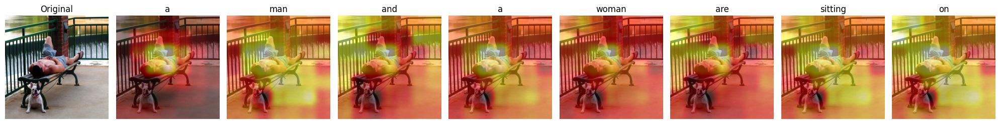

✅ Sauvegardé : attention_hard.png

Image : 101093029.jpg
Caption générée : a man in a blue shirt is walking down a street


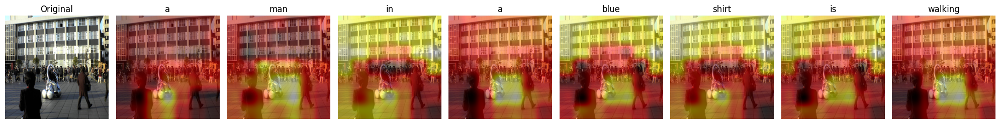

✅ Sauvegardé : attention_hard.png

Image : 101362650.jpg
Caption générée : a man in a white shirt is dancing with a woman in a white shirt


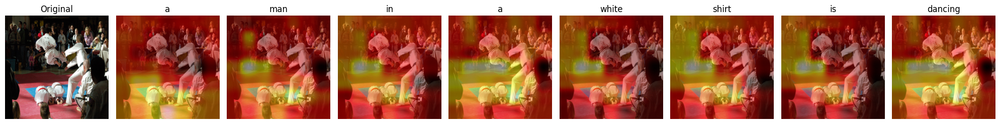

✅ Sauvegardé : attention_hard.png


In [22]:
import matplotlib.pyplot as plt
import numpy as np

def visualize_attention_hard(image_path, encoder, decoder_hard, word2idx, idx2word):
    raw_image    = Image.open(image_path).convert("RGB")
    image_tensor = transform(raw_image)

    caption, alphas = generate_caption_hard(
        encoder, decoder_hard, image_tensor, word2idx, idx2word
    )

    print(f"Caption générée : {' '.join(caption)}")

    fig, axes = plt.subplots(1, min(len(caption), 8) + 1, figsize=(20, 4))

    axes[0].imshow(raw_image.resize((224, 224)))
    axes[0].set_title("Original")
    axes[0].axis("off")

    for i, (word, alpha) in enumerate(zip(caption[:8], alphas[:8])):
        alpha_np = alpha.numpy().reshape(14, 14)
        alpha_np = np.array(Image.fromarray(alpha_np).resize(
            (224, 224), Image.LANCZOS)
        )
        axes[i+1].imshow(raw_image.resize((224, 224)))
        axes[i+1].imshow(alpha_np, alpha=0.5, cmap="hot")
        axes[i+1].set_title(word)
        axes[i+1].axis("off")

    plt.tight_layout()
    plt.savefig("attention_hard.png", dpi=100, bbox_inches="tight")
    plt.show()
    print("✅ Sauvegardé : attention_hard.png")

# Tester sur les mêmes images que Soft
test_images = test_df["image"].unique()[:3]
for img_name in test_images:
    img_path = os.path.join(IMG_DIR, img_name)
    print(f"\nImage : {img_name}")
    visualize_attention_hard(img_path, encoder, decoder_hard, word2idx, idx2word)

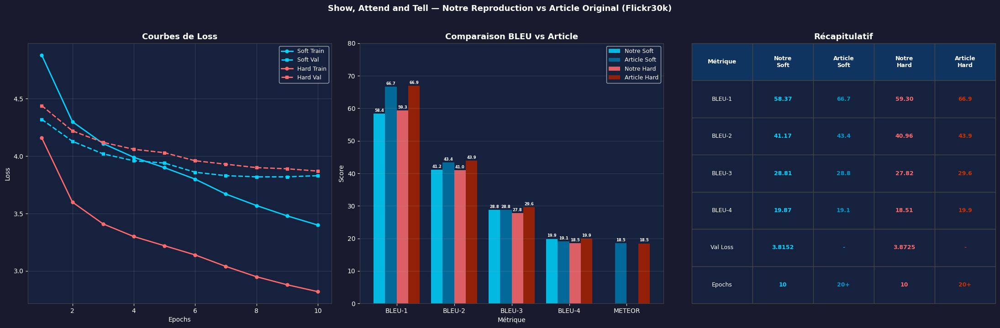

✅ Rapport sauvegardé : rapport_final.png


In [23]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(22, 7))
fig.patch.set_facecolor("#1a1a2e")

# ======== 1. Courbes de loss ========
ax = axes[0]
ax.set_facecolor("#16213e")

epochs_range = range(1, 11)
train_soft = [4.88, 4.30, 4.11, 3.99, 3.90, 3.80, 3.67, 3.57, 3.48, 3.40]
val_soft   = [4.32, 4.13, 4.02, 3.96, 3.94, 3.86, 3.83, 3.82, 3.82, 3.83]
train_hard = [4.16, 3.60, 3.41, 3.30, 3.22, 3.14, 3.04, 2.95, 2.88, 2.82]
val_hard   = [4.44, 4.22, 4.12, 4.06, 4.03, 3.96, 3.93, 3.90, 3.89, 3.87]

ax.plot(epochs_range, train_soft, color="#00d4ff", linewidth=2,
        linestyle="-",  marker="o", markersize=5, label="Soft Train")
ax.plot(epochs_range, val_soft,   color="#00d4ff", linewidth=2,
        linestyle="--", marker="s", markersize=5, label="Soft Val")
ax.plot(epochs_range, train_hard, color="#ff6b6b", linewidth=2,
        linestyle="-",  marker="o", markersize=5, label="Hard Train")
ax.plot(epochs_range, val_hard,   color="#ff6b6b", linewidth=2,
        linestyle="--", marker="s", markersize=5, label="Hard Val")

ax.set_title("Courbes de Loss", color="white", fontsize=13, fontweight="bold")
ax.set_xlabel("Epochs", color="white")
ax.set_ylabel("Loss", color="white")
ax.tick_params(colors="white")
ax.legend(facecolor="#16213e", labelcolor="white", fontsize=9)
ax.grid(True, alpha=0.2)
for spine in ax.spines.values():
    spine.set_edgecolor("#444")

# ======== 2. BLEU Scores comparaison ========
ax = axes[1]
ax.set_facecolor("#16213e")

metrics = ["BLEU-1", "BLEU-2", "BLEU-3", "BLEU-4", "METEOR"]

# Nos résultats
our_soft  = [58.37, 41.17, 28.81, 19.87, 0]   # METEOR pas calculé
our_hard  = [59.30, 40.96, 27.82, 18.51, 0]

# Article original
art_soft  = [66.7, 43.4, 28.8, 19.1, 18.49]
art_hard  = [66.9, 43.9, 29.6, 19.9, 18.46]

x     = np.arange(len(metrics))
width = 0.2

bars1 = ax.bar(x - 1.5*width, our_soft,  width, color="#00d4ff", alpha=0.85, label="Notre Soft")
bars2 = ax.bar(x - 0.5*width, art_soft,  width, color="#0077aa", alpha=0.85, label="Article Soft")
bars3 = ax.bar(x + 0.5*width, our_hard,  width, color="#ff6b6b", alpha=0.85, label="Notre Hard")
bars4 = ax.bar(x + 1.5*width, art_hard,  width, color="#aa2200", alpha=0.85, label="Article Hard")

for bars in [bars1, bars2, bars3, bars4]:
    for bar in bars:
        h = bar.get_height()
        if h > 0:
            ax.text(bar.get_x() + bar.get_width()/2., h + 0.3,
                    f"{h:.1f}", ha="center", va="bottom",
                    color="white", fontsize=6, fontweight="bold")

ax.set_title("Comparaison BLEU vs Article", color="white", fontsize=13, fontweight="bold")
ax.set_xlabel("Métrique", color="white")
ax.set_ylabel("Score", color="white")
ax.set_xticks(x)
ax.set_xticklabels(metrics, color="white")
ax.tick_params(colors="white")
ax.legend(facecolor="#16213e", labelcolor="white", fontsize=9)
ax.grid(True, alpha=0.2, axis="y")
ax.set_ylim(0, 80)
for spine in ax.spines.values():
    spine.set_edgecolor("#444")

# ======== 3. Tableau récapitulatif ========
ax = axes[2]
ax.set_facecolor("#16213e")
ax.axis("off")

table_data = [
    ["Métrique",   "Notre\nSoft", "Article\nSoft", "Notre\nHard", "Article\nHard"],
    ["BLEU-1",     "58.37",       "66.7",           "59.30",       "66.9"],
    ["BLEU-2",     "41.17",       "43.4",           "40.96",       "43.9"],
    ["BLEU-3",     "28.81",       "28.8",           "27.82",       "29.6"],
    ["BLEU-4",     "19.87",       "19.1",           "18.51",       "19.9"],
    ["Val Loss",   "3.8152",      "-",              "3.8725",      "-"],
    ["Epochs",     "10",          "20+",            "10",          "20+"],
]

table = ax.table(
    cellText  = table_data[1:],
    colLabels = table_data[0],
    cellLoc   = "center",
    loc       = "center",
    bbox      = [0, 0, 1, 1]
)

table.auto_set_font_size(False)
table.set_fontsize(9)

for (row, col), cell in table.get_celld().items():
    cell.set_facecolor("#16213e")
    cell.set_edgecolor("#444")
    if row == 0:
        cell.set_facecolor("#0f3460")
        cell.set_text_props(color="white", fontweight="bold")
    elif col == 1:
        cell.set_text_props(color="#00d4ff", fontweight="bold")
    elif col == 2:
        cell.set_text_props(color="#0099cc", fontweight="bold")
    elif col == 3:
        cell.set_text_props(color="#ff6b6b", fontweight="bold")
    elif col == 4:
        cell.set_text_props(color="#cc3300", fontweight="bold")
    else:
        cell.set_text_props(color="white")

ax.set_title("Récapitulatif", color="white", fontsize=13, fontweight="bold")

plt.suptitle("Show, Attend and Tell — Notre Reproduction vs Article Original (Flickr30k)",
             fontsize=13, color="white", fontweight="bold", y=1.02)

plt.tight_layout()
plt.savefig("rapport_final.png", dpi=150, bbox_inches="tight", facecolor="#1a1a2e")
plt.show()
print("✅ Rapport sauvegardé : rapport_final.png")

## Partie 9 — Analyse d'erreurs — Hard Attention

[nltk_data] Downloading package punkt to /usr/share/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /usr/share/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /usr/share/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package wordnet to /usr/share/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


✅ Modèles rechargés !

Génération des captions pour analyse...
  100/500 traitées...
  200/500 traitées...
  300/500 traitées...
  400/500 traitées...
  500/500 traitées...
✅ 500 captions générées !

=== Catégories d'erreurs ===
  incorrect_object     : 441
  incorrect_action     : 317
  omitted_object       : 100
  repetition           : 447
  gender_error         : 142

Top 10 noms incorrects  : [('shirt', 164), ('man', 67), ('woman', 56), ('jean', 35), ('bench', 32), ('group', 31), ('front', 27), ('street', 22), ('peopl', 17), ('pink', 16)]
Top 10 verbes incorrects: [('is', 75), ('stand', 55), ('are', 54), ('sit', 48), ('walk', 24), ('hold', 21), ('run', 17), ('jump', 17), ('play', 15), ('ride', 14)]


/tmp/ipykernel_57/1894793316.py:169: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(cats, rotation=20, ha="right", color="white", fontsize=8)


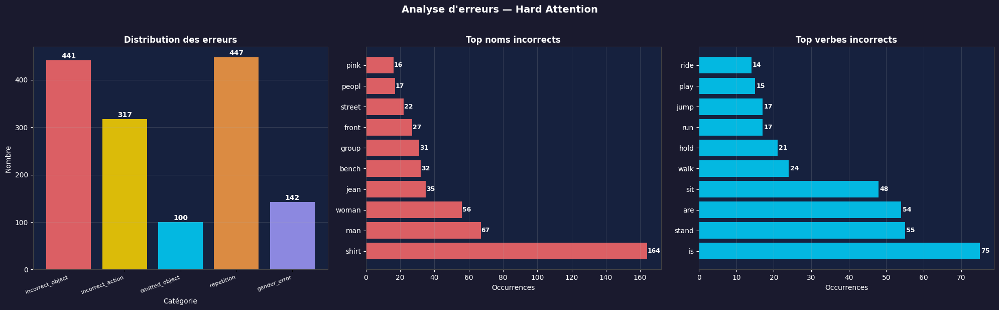

✅ Sauvegardé : error_analysis.png


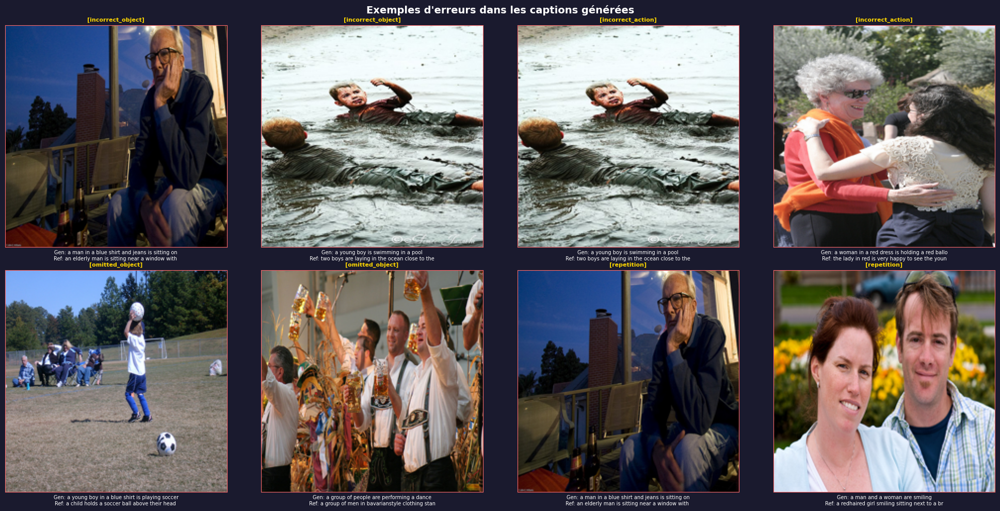

✅ Sauvegardé : error_examples.png


In [25]:
import nltk
from nltk import pos_tag, word_tokenize
from nltk.stem import PorterStemmer
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from PIL import Image
import os

# Fix nltk downloads
nltk.download('punkt')
nltk.download('averaged_perceptron_tagger')
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('wordnet')

stemmer = PorterStemmer()

# ============================================
# RECHARGER LES MODELES
# ============================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Encoder
encoder = Encoder(encoded_image_size=14).to(device)

# Decoder Hard
decoder_hard = DecoderWithHardAttention(
    attention_dim = ATTENTION_DIM,
    embed_dim     = EMBED_DIM,
    decoder_dim   = DECODER_DIM,
    vocab_size    = VOCAB_SIZE,
    encoder_dim   = ENCODER_DIM,
    dropout       = DROPOUT
).to(device)

# Charger les poids
encoder.load_state_dict(checkpoint_hard["encoder_state_dict"])
decoder_hard.load_state_dict(checkpoint_hard["decoder_state_dict"])
encoder.eval()
decoder_hard.eval()
print("✅ Modèles rechargés !")

# ============================================
# GÉNÉRER CAPTIONS POUR ANALYSE
# ============================================
print("\nGénération des captions pour analyse...")

test_groups   = test_df.groupby("image")["caption"].apply(list).reset_index()
sample_groups = test_groups.sample(500, random_state=42).reset_index(drop=True)

generated_captions = []
reference_captions = []
image_names        = []

for idx, row in sample_groups.iterrows():
    img_path = os.path.join(IMG_DIR, row["image"])
    try:
        image = Image.open(img_path).convert("RGB")
        image = transform(image)
    except:
        continue

    generated, _ = generate_caption_hard(
        encoder, decoder_hard, image, word2idx, idx2word
    )

    generated_captions.append(" ".join(generated))
    reference_captions.append([clean_caption(c) for c in row["caption"]])
    image_names.append(row["image"])

    if (idx + 1) % 100 == 0:
        print(f"  {idx+1}/500 traitées...")

print(f"✅ {len(generated_captions)} captions générées !")


# ============================================
# ANALYSE AUTOMATIQUE
# ============================================
def get_nouns_verbs(text):
    tokens = word_tokenize(text.lower())
    tagged = pos_tag(tokens)
    nouns  = [stemmer.stem(w) for w, t in tagged if t.startswith("NN")]
    verbs  = [stemmer.stem(w) for w, t in tagged if t.startswith("VB")]
    return set(nouns), set(verbs)

incorrect_nouns = []
incorrect_verbs = []
error_categories = {
    "incorrect_object"  : 0,
    "incorrect_action"  : 0,
    "omitted_object"    : 0,
    "repetition"        : 0,
    "gender_error"      : 0,
}

for gen, refs in zip(generated_captions, reference_captions):
    gen_nouns, gen_verbs = get_nouns_verbs(gen)

    ref_nouns_all = set()
    ref_verbs_all = set()
    for ref in refs:
        rn, rv = get_nouns_verbs(ref)
        ref_nouns_all |= rn
        ref_verbs_all |= rv

    wrong_nouns = gen_nouns - ref_nouns_all
    wrong_verbs = gen_verbs - ref_verbs_all

    incorrect_nouns.extend(wrong_nouns)
    incorrect_verbs.extend(wrong_verbs)

    if wrong_nouns:
        error_categories["incorrect_object"] += 1
    if wrong_verbs:
        error_categories["incorrect_action"] += 1

    ref_nouns_list = [get_nouns_verbs(r)[0] for r in refs]
    if ref_nouns_list:
        ref_nouns_common = set.intersection(*ref_nouns_list)
        if ref_nouns_common - gen_nouns:
            error_categories["omitted_object"] += 1

    words = gen.split()
    if len(words) != len(set(words)):
        error_categories["repetition"] += 1

    gen_lower = gen.lower()
    for ref in refs:
        if ("man" in gen_lower and "woman" in ref.lower()) or \
           ("woman" in gen_lower and "man" in ref.lower()):
            error_categories["gender_error"] += 1
            break

print("\n=== Catégories d'erreurs ===")
for cat, count in error_categories.items():
    print(f"  {cat:<20} : {count}")

top_nouns = Counter(incorrect_nouns).most_common(10)
top_verbs = Counter(incorrect_verbs).most_common(10)
print(f"\nTop 10 noms incorrects  : {top_nouns}")
print(f"Top 10 verbes incorrects: {top_verbs}")


# ============================================
# VISUALISATION ANALYSE D'ERREURS
# ============================================
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.patch.set_facecolor("#1a1a2e")

# 1. Distribution des erreurs
ax = axes[0]
ax.set_facecolor("#16213e")
cats   = list(error_categories.keys())
counts = list(error_categories.values())
colors = ["#ff6b6b", "#ffd700", "#00d4ff", "#ff9f43", "#a29bfe"]
bars   = ax.bar(cats, counts, color=colors, alpha=0.85)
for bar, count in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 1,
            str(count), ha="center", va="bottom",
            color="white", fontsize=10, fontweight="bold")
ax.set_title("Distribution des erreurs", color="white",
             fontsize=12, fontweight="bold")
ax.set_xlabel("Catégorie", color="white")
ax.set_ylabel("Nombre", color="white")
ax.tick_params(colors="white", axis="y")
ax.set_xticklabels(cats, rotation=20, ha="right", color="white", fontsize=8)
ax.grid(True, alpha=0.2, axis="y")
for spine in ax.spines.values():
    spine.set_edgecolor("#444")

# 2. Top noms incorrects
ax = axes[1]
ax.set_facecolor("#16213e")
nouns_labels = [n[0] for n in top_nouns]
nouns_counts = [n[1] for n in top_nouns]
bars = ax.barh(nouns_labels, nouns_counts, color="#ff6b6b", alpha=0.85)
for bar, count in zip(bars, nouns_counts):
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2.,
            str(count), ha="left", va="center",
            color="white", fontsize=9, fontweight="bold")
ax.set_title("Top noms incorrects", color="white",
             fontsize=12, fontweight="bold")
ax.set_xlabel("Occurrences", color="white")
ax.tick_params(colors="white")
ax.grid(True, alpha=0.2, axis="x")
for spine in ax.spines.values():
    spine.set_edgecolor("#444")

# 3. Top verbes incorrects
ax = axes[2]
ax.set_facecolor("#16213e")
verbs_labels = [v[0] for v in top_verbs]
verbs_counts = [v[1] for v in top_verbs]
bars = ax.barh(verbs_labels, verbs_counts, color="#00d4ff", alpha=0.85)
for bar, count in zip(bars, verbs_counts):
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2.,
            str(count), ha="left", va="center",
            color="white", fontsize=9, fontweight="bold")
ax.set_title("Top verbes incorrects", color="white",
             fontsize=12, fontweight="bold")
ax.set_xlabel("Occurrences", color="white")
ax.tick_params(colors="white")
ax.grid(True, alpha=0.2, axis="x")
for spine in ax.spines.values():
    spine.set_edgecolor("#444")

plt.suptitle("Analyse d'erreurs — Hard Attention",
             fontsize=14, color="white", fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("error_analysis.png", dpi=150, bbox_inches="tight",
            facecolor="#1a1a2e")
plt.show()
print("✅ Sauvegardé : error_analysis.png")


# ============================================
# EXEMPLES VISUELS D'ERREURS
# ============================================
examples = {"incorrect_object": [], "incorrect_action": [],
            "omitted_object":   [], "repetition":       []}

for gen, refs, img_name in zip(generated_captions,
                                reference_captions, image_names):
    gen_nouns, gen_verbs = get_nouns_verbs(gen)
    ref_nouns_all = set()
    ref_verbs_all = set()
    for ref in refs:
        rn, rv = get_nouns_verbs(ref)
        ref_nouns_all |= rn
        ref_verbs_all |= rv

    if len(examples["incorrect_object"]) < 2:
        if gen_nouns - ref_nouns_all:
            examples["incorrect_object"].append((img_name, gen, refs[0]))

    if len(examples["incorrect_action"]) < 2:
        if gen_verbs - ref_verbs_all:
            examples["incorrect_action"].append((img_name, gen, refs[0]))

    if len(examples["omitted_object"]) < 2:
        ref_nouns_list = [get_nouns_verbs(r)[0] for r in refs]
        if ref_nouns_list:
            ref_nouns_common = set.intersection(*ref_nouns_list)
            if ref_nouns_common - gen_nouns:
                examples["omitted_object"].append((img_name, gen, refs[0]))

    if len(examples["repetition"]) < 2:
        words = gen.split()
        if len(words) != len(set(words)):
            examples["repetition"].append((img_name, gen, refs[0]))

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
fig.patch.set_facecolor("#1a1a2e")

plot_idx = 0
for cat, exs in examples.items():
    for img_name, gen, ref in exs[:2]:
        if plot_idx >= 8:
            break
        row = plot_idx // 4
        col = plot_idx % 4
        ax  = axes[row][col]
        try:
            img = Image.open(os.path.join(IMG_DIR, img_name)).resize((224, 224))
            ax.imshow(img)
        except:
            ax.axis("off")
            plot_idx += 1
            continue
        ax.set_title(f"[{cat}]", color="#ffd700", fontsize=8, fontweight="bold")
        ax.set_xlabel(
            f"Gen: {gen[:45]}\nRef: {ref[:45]}",
            color="white", fontsize=7
        )
        ax.tick_params(left=False, bottom=False,
                       labelleft=False, labelbottom=False)
        for spine in ax.spines.values():
            spine.set_edgecolor("#ff6b6b")
        plot_idx += 1

for i in range(plot_idx, 8):
    axes[i//4][i%4].axis("off")

plt.suptitle("Exemples d'erreurs dans les captions générées",
             fontsize=14, color="white", fontweight="bold")
plt.tight_layout()
plt.savefig("error_examples.png", dpi=150, bbox_inches="tight",
            facecolor="#1a1a2e")
plt.show()
print("✅ Sauvegardé : error_examples.png")

## Partie 10 — Analyse d'erreurs — Soft Attention

[nltk_data] Downloading package punkt to /usr/share/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /usr/share/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /usr/share/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package wordnet to /usr/share/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


✅ Soft Attention chargé !

Génération des captions Soft pour analyse...
  100/500 traitées...
  200/500 traitées...
  300/500 traitées...
  400/500 traitées...
  500/500 traitées...
✅ 500 captions générées !

=== Catégories d'erreurs Soft ===
  incorrect_object     : 413
  incorrect_action     : 304
  omitted_object       : 98
  repetition           : 440
  gender_error         : 121

Top 10 noms incorrects  : [('shirt', 114), ('man', 55), ('woman', 41), ('pant', 30), ('front', 25), ('group', 23), ('men', 22), ('jacket', 17), ('blue', 16), ('peopl', 16)]
Top 10 verbes incorrects: [('is', 77), ('stand', 50), ('are', 49), ('sit', 32), ('walk', 30), ('play', 23), ('hold', 20), ('jump', 13), ('look', 11), ('ride', 9)]


/tmp/ipykernel_57/655212214.py:149: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(cats, rotation=20, ha="right", color="white", fontsize=8)


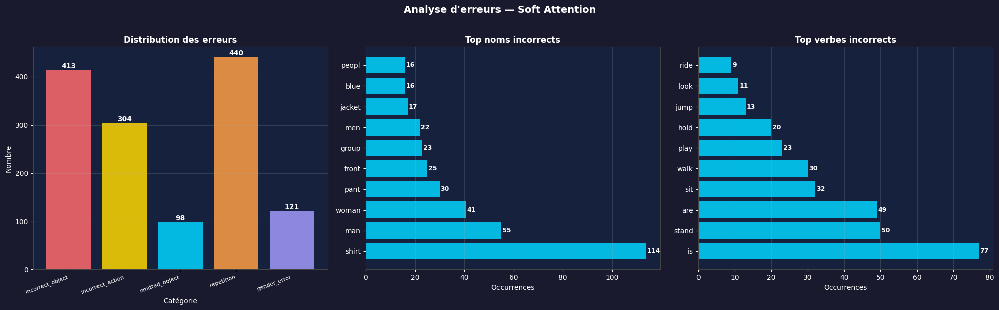

✅ Sauvegardé : error_analysis_soft.png


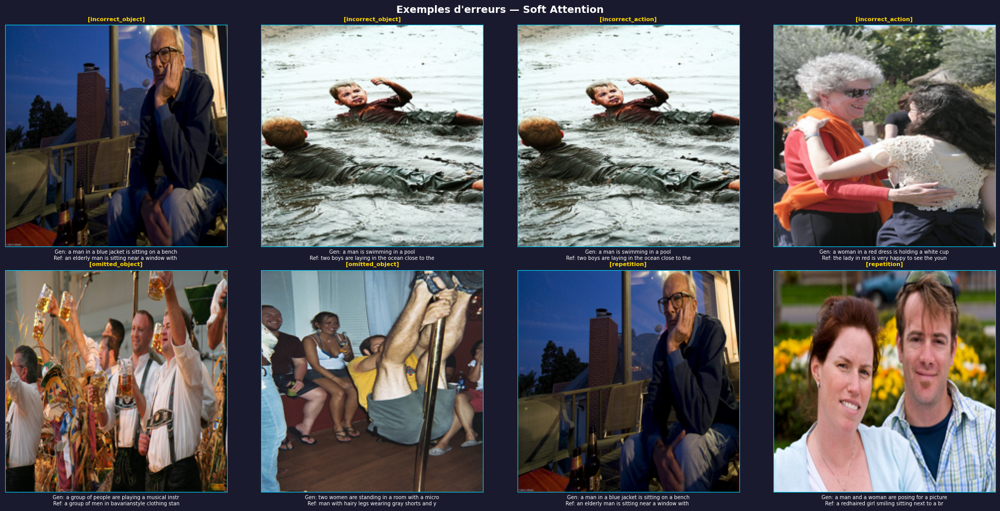

✅ Sauvegardé : error_examples_soft.png


In [28]:
import nltk
from nltk import pos_tag, word_tokenize
from nltk.stem import PorterStemmer
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np

nltk.download('punkt')
nltk.download('averaged_perceptron_tagger')
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('wordnet')

stemmer = PorterStemmer()

# ============================================
# CHARGER SOFT ATTENTION
# ============================================
checkpoint_soft = torch.load("/kaggle/input/models/ikbelhamdi/best-soft-attention-pth/other/default/1/best_soft_attention (1).pth")
encoder.load_state_dict(checkpoint_soft["encoder_state_dict"])
decoder.load_state_dict(checkpoint_soft["decoder_state_dict"])
encoder.eval()
decoder.eval()
print("✅ Soft Attention chargé !")

# ============================================
# GÉNÉRER CAPTIONS SOFT POUR ANALYSE
# ============================================
print("\nGénération des captions Soft pour analyse...")

test_groups_soft   = test_df.groupby("image")["caption"].apply(list).reset_index()
sample_groups_soft = test_groups_soft.sample(500, random_state=42).reset_index(drop=True)

generated_captions_soft = []
reference_captions_soft = []
image_names_soft        = []

for idx, row in sample_groups_soft.iterrows():
    img_path = os.path.join(IMG_DIR, row["image"])
    try:
        image = Image.open(img_path).convert("RGB")
        image = transform(image)
    except:
        continue

    generated, _ = generate_caption(
        encoder, decoder, image, word2idx, idx2word
    )

    generated_captions_soft.append(" ".join(generated))
    reference_captions_soft.append([clean_caption(c) for c in row["caption"]])
    image_names_soft.append(row["image"])

    if (idx + 1) % 100 == 0:
        print(f"  {idx+1}/500 traitées...")

print(f"✅ {len(generated_captions_soft)} captions générées !")


# ============================================
# ANALYSE AUTOMATIQUE SOFT
# ============================================
def get_nouns_verbs(text):
    tokens = word_tokenize(text.lower())
    tagged = pos_tag(tokens)
    nouns  = [stemmer.stem(w) for w, t in tagged if t.startswith("NN")]
    verbs  = [stemmer.stem(w) for w, t in tagged if t.startswith("VB")]
    return set(nouns), set(verbs)

incorrect_nouns_soft = []
incorrect_verbs_soft = []
error_categories_soft = {
    "incorrect_object" : 0,
    "incorrect_action" : 0,
    "omitted_object"   : 0,
    "repetition"       : 0,
    "gender_error"     : 0,
}

for gen, refs in zip(generated_captions_soft, reference_captions_soft):
    gen_nouns, gen_verbs = get_nouns_verbs(gen)

    ref_nouns_all = set()
    ref_verbs_all = set()
    for ref in refs:
        rn, rv = get_nouns_verbs(ref)
        ref_nouns_all |= rn
        ref_verbs_all |= rv

    wrong_nouns = gen_nouns - ref_nouns_all
    wrong_verbs = gen_verbs - ref_verbs_all

    incorrect_nouns_soft.extend(wrong_nouns)
    incorrect_verbs_soft.extend(wrong_verbs)

    if wrong_nouns:
        error_categories_soft["incorrect_object"] += 1
    if wrong_verbs:
        error_categories_soft["incorrect_action"] += 1

    ref_nouns_list = [get_nouns_verbs(r)[0] for r in refs]
    if ref_nouns_list:
        ref_nouns_common = set.intersection(*ref_nouns_list)
        if ref_nouns_common - gen_nouns:
            error_categories_soft["omitted_object"] += 1

    words = gen.split()
    if len(words) != len(set(words)):
        error_categories_soft["repetition"] += 1

    gen_lower = gen.lower()
    for ref in refs:
        if ("man" in gen_lower and "woman" in ref.lower()) or \
           ("woman" in gen_lower and "man" in ref.lower()):
            error_categories_soft["gender_error"] += 1
            break

print("\n=== Catégories d'erreurs Soft ===")
for cat, count in error_categories_soft.items():
    print(f"  {cat:<20} : {count}")

top_nouns_soft = Counter(incorrect_nouns_soft).most_common(10)
top_verbs_soft = Counter(incorrect_verbs_soft).most_common(10)
print(f"\nTop 10 noms incorrects  : {top_nouns_soft}")
print(f"Top 10 verbes incorrects: {top_verbs_soft}")


# ============================================
# VISUALISATION SOFT
# ============================================
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.patch.set_facecolor("#1a1a2e")

# 1. Distribution des erreurs
ax = axes[0]
ax.set_facecolor("#16213e")
cats   = list(error_categories_soft.keys())
counts = list(error_categories_soft.values())
colors = ["#ff6b6b", "#ffd700", "#00d4ff", "#ff9f43", "#a29bfe"]
bars   = ax.bar(cats, counts, color=colors, alpha=0.85)
for bar, count in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 1,
            str(count), ha="center", va="bottom",
            color="white", fontsize=10, fontweight="bold")
ax.set_title("Distribution des erreurs", color="white",
             fontsize=12, fontweight="bold")
ax.set_xlabel("Catégorie", color="white")
ax.set_ylabel("Nombre", color="white")
ax.tick_params(colors="white", axis="y")
ax.set_xticklabels(cats, rotation=20, ha="right", color="white", fontsize=8)
ax.grid(True, alpha=0.2, axis="y")
for spine in ax.spines.values():
    spine.set_edgecolor("#444")

# 2. Top noms incorrects
ax = axes[1]
ax.set_facecolor("#16213e")
nouns_labels = [n[0] for n in top_nouns_soft]
nouns_counts = [n[1] for n in top_nouns_soft]
bars = ax.barh(nouns_labels, nouns_counts, color="#00d4ff", alpha=0.85)
for bar, count in zip(bars, nouns_counts):
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2.,
            str(count), ha="left", va="center",
            color="white", fontsize=9, fontweight="bold")
ax.set_title("Top noms incorrects", color="white",
             fontsize=12, fontweight="bold")
ax.set_xlabel("Occurrences", color="white")
ax.tick_params(colors="white")
ax.grid(True, alpha=0.2, axis="x")
for spine in ax.spines.values():
    spine.set_edgecolor("#444")

# 3. Top verbes incorrects
ax = axes[2]
ax.set_facecolor("#16213e")
verbs_labels = [v[0] for v in top_verbs_soft]
verbs_counts = [v[1] for v in top_verbs_soft]
bars = ax.barh(verbs_labels, verbs_counts, color="#00d4ff", alpha=0.85)
for bar, count in zip(bars, verbs_counts):
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2.,
            str(count), ha="left", va="center",
            color="white", fontsize=9, fontweight="bold")
ax.set_title("Top verbes incorrects", color="white",
             fontsize=12, fontweight="bold")
ax.set_xlabel("Occurrences", color="white")
ax.tick_params(colors="white")
ax.grid(True, alpha=0.2, axis="x")
for spine in ax.spines.values():
    spine.set_edgecolor("#444")

plt.suptitle("Analyse d'erreurs — Soft Attention",
             fontsize=14, color="white", fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("error_analysis_soft.png", dpi=150, bbox_inches="tight",
            facecolor="#1a1a2e")
plt.show()
print("✅ Sauvegardé : error_analysis_soft.png")


# ============================================
# EXEMPLES VISUELS D'ERREURS SOFT
# ============================================
examples_soft = {"incorrect_object": [], "incorrect_action": [],
                 "omitted_object":   [], "repetition":       []}

for gen, refs, img_name in zip(generated_captions_soft,
                                reference_captions_soft,
                                image_names_soft):
    gen_nouns, gen_verbs = get_nouns_verbs(gen)
    ref_nouns_all = set()
    ref_verbs_all = set()
    for ref in refs:
        rn, rv = get_nouns_verbs(ref)
        ref_nouns_all |= rn
        ref_verbs_all |= rv

    if len(examples_soft["incorrect_object"]) < 2:
        if gen_nouns - ref_nouns_all:
            examples_soft["incorrect_object"].append((img_name, gen, refs[0]))

    if len(examples_soft["incorrect_action"]) < 2:
        if gen_verbs - ref_verbs_all:
            examples_soft["incorrect_action"].append((img_name, gen, refs[0]))

    if len(examples_soft["omitted_object"]) < 2:
        ref_nouns_list = [get_nouns_verbs(r)[0] for r in refs]
        if ref_nouns_list:
            ref_nouns_common = set.intersection(*ref_nouns_list)
            if ref_nouns_common - gen_nouns:
                examples_soft["omitted_object"].append((img_name, gen, refs[0]))

    if len(examples_soft["repetition"]) < 2:
        words = gen.split()
        if len(words) != len(set(words)):
            examples_soft["repetition"].append((img_name, gen, refs[0]))

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
fig.patch.set_facecolor("#1a1a2e")

plot_idx = 0
for cat, exs in examples_soft.items():
    for img_name, gen, ref in exs[:2]:
        if plot_idx >= 8:
            break
        row = plot_idx // 4
        col = plot_idx % 4
        ax  = axes[row][col]
        try:
            img = Image.open(os.path.join(IMG_DIR, img_name)).resize((224, 224))
            ax.imshow(img)
        except:
            ax.axis("off")
            plot_idx += 1
            continue
        ax.set_title(f"[{cat}]", color="#ffd700", fontsize=8, fontweight="bold")
        ax.set_xlabel(
            f"Gen: {gen[:45]}\nRef: {ref[:45]}",
            color="white", fontsize=7
        )
        ax.tick_params(left=False, bottom=False,
                       labelleft=False, labelbottom=False)
        for spine in ax.spines.values():
            spine.set_edgecolor("#00d4ff")
        plot_idx += 1

for i in range(plot_idx, 8):
    axes[i//4][i%4].axis("off")

plt.suptitle("Exemples d'erreurs — Soft Attention",
             fontsize=14, color="white", fontweight="bold")
plt.tight_layout()
plt.savefig("error_examples_soft.png", dpi=150, bbox_inches="tight",
            facecolor="#1a1a2e")
plt.show()
print("✅ Sauvegardé : error_examples_soft.png")

## Partie 10 — Framework de Correction
### VGG19 + GPT2 — Hard Attention

In [5]:
import torch
import torch.nn as nn
import torchvision.models as models
from PIL import Image

# ============ HYPERPARAMETRES ============
ENCODER_DIM   = 2048
ATTENTION_DIM = 512
EMBED_DIM     = 512
DECODER_DIM   = 512
VOCAB_SIZE    = len(word2idx)
DROPOUT       = 0.5

# ============ ENCODER ============
class Encoder(nn.Module):
    def __init__(self, encoded_image_size=14):
        super(Encoder, self).__init__()
        self.enc_image_size = encoded_image_size
        resnet              = models.resnet101(weights="IMAGENET1K_V1")
        modules             = list(resnet.children())[:-2]
        self.resnet         = nn.Sequential(*modules)
        self.adaptive_pool  = nn.AdaptiveAvgPool2d((encoded_image_size, encoded_image_size))
        self.fine_tune(fine_tune=False)

    def forward(self, images):
        features = self.resnet(images)
        features = self.adaptive_pool(features)
        features = features.permute(0, 2, 3, 1)
        return features

    def fine_tune(self, fine_tune=True):
        for p in self.resnet.parameters():
            p.requires_grad = False
        if fine_tune:
            for c in list(self.resnet.children())[5:]:
                for p in c.parameters():
                    p.requires_grad = True

# ============ HARD ATTENTION ============
class HardAttention(nn.Module):
    def __init__(self, encoder_dim, decoder_dim, attention_dim):
        super(HardAttention, self).__init__()
        self.encoder_att = nn.Linear(encoder_dim, attention_dim)
        self.decoder_att = nn.Linear(decoder_dim, attention_dim)
        self.full_att    = nn.Linear(attention_dim, 1)
        self.relu        = nn.ReLU()
        self.softmax     = nn.Softmax(dim=1)

    def forward(self, encoder_out, decoder_hidden):
        att1  = self.encoder_att(encoder_out)
        att2  = self.decoder_att(decoder_hidden)
        att   = self.full_att(self.relu(att1 + att2.unsqueeze(1))).squeeze(2)
        alpha = self.softmax(att)
        if self.training:
            dist       = torch.distributions.Categorical(alpha)
            selected   = dist.sample()
            log_prob   = dist.log_prob(selected)
            hard_alpha = torch.zeros_like(alpha)
            hard_alpha.scatter_(1, selected.unsqueeze(1), 1)
            context    = (encoder_out * hard_alpha.unsqueeze(2)).sum(dim=1)
            return context, alpha, log_prob
        else:
            context = (encoder_out * alpha.unsqueeze(2)).sum(dim=1)
            return context, alpha, None

# ============ DECODER HARD ============
class DecoderWithHardAttention(nn.Module):
    def __init__(self, attention_dim, embed_dim, decoder_dim,
                 vocab_size, encoder_dim=2048, dropout=0.5):
        super(DecoderWithHardAttention, self).__init__()
        self.attention_dim = attention_dim
        self.embed_dim     = embed_dim
        self.decoder_dim   = decoder_dim
        self.vocab_size    = vocab_size
        self.encoder_dim   = encoder_dim
        self.attention     = HardAttention(encoder_dim, decoder_dim, attention_dim)
        self.embedding     = nn.Embedding(vocab_size, embed_dim)
        self.dropout       = nn.Dropout(p=dropout)
        self.lstm_cell     = nn.LSTMCell(embed_dim + encoder_dim, decoder_dim)
        self.fc            = nn.Linear(decoder_dim, vocab_size)
        self.init_h        = nn.Linear(encoder_dim, decoder_dim)
        self.init_c        = nn.Linear(encoder_dim, decoder_dim)
        self._init_weights()

    def _init_weights(self):
        self.embedding.weight.data.uniform_(-0.1, 0.1)
        self.fc.bias.data.fill_(0)
        self.fc.weight.data.uniform_(-0.1, 0.1)

    def init_hidden_state(self, encoder_out):
        mean = encoder_out.mean(dim=1)
        return torch.tanh(self.init_h(mean)), torch.tanh(self.init_c(mean))

    def forward(self, encoder_out, captions, lengths):
        batch_size  = encoder_out.shape[0]
        encoder_dim = encoder_out.shape[-1]
        encoder_out = encoder_out.view(batch_size, -1, encoder_dim)
        num_pixels  = encoder_out.shape[1]
        lengths, sort_idx = lengths.sort(dim=0, descending=True)
        encoder_out       = encoder_out[sort_idx]
        captions          = captions[sort_idx]
        embeddings        = self.embedding(captions)
        h, c              = self.init_hidden_state(encoder_out)
        decode_lengths    = (lengths - 1).tolist()
        max_decode_len    = max(decode_lengths)
        predictions       = torch.zeros(batch_size, max_decode_len, self.vocab_size).to(encoder_out.device)
        alphas            = torch.zeros(batch_size, max_decode_len, num_pixels).to(encoder_out.device)
        log_probs         = torch.zeros(batch_size, max_decode_len).to(encoder_out.device)
        for t in range(max_decode_len):
            batch_size_t = sum([l > t for l in decode_lengths])
            if self.training:
                context, alpha, log_prob = self.attention(encoder_out[:batch_size_t], h[:batch_size_t])
                log_probs[:batch_size_t, t] = log_prob
            else:
                context, alpha, _ = self.attention(encoder_out[:batch_size_t], h[:batch_size_t])
            lstm_input = torch.cat([embeddings[:batch_size_t, t, :], context], dim=1)
            h, c       = self.lstm_cell(lstm_input, (h[:batch_size_t], c[:batch_size_t]))
            preds      = self.fc(self.dropout(h))
            predictions[:batch_size_t, t, :] = preds
            alphas[:batch_size_t, t, :]      = alpha
        return predictions, captions, decode_lengths, alphas, log_probs, sort_idx

# ============ CHARGER MODELES ============
encoder      = Encoder(encoded_image_size=14).to(device)
decoder_hard = DecoderWithHardAttention(
    attention_dim=ATTENTION_DIM, embed_dim=EMBED_DIM,
    decoder_dim=DECODER_DIM, vocab_size=VOCAB_SIZE,
    encoder_dim=ENCODER_DIM, dropout=DROPOUT
).to(device)

checkpoint_hard = torch.load("/kaggle/input/models/ikbelhamdi/best-hard-attention-pth/other/default/1/best_hard_attention.pth")
encoder.load_state_dict(checkpoint_hard["encoder_state_dict"])
decoder_hard.load_state_dict(checkpoint_hard["decoder_state_dict"])
encoder.eval()
decoder_hard.eval()
print("✅ Encoder + Decoder Hard chargés !")

# ============ FONCTION GENERATE HARD ============
def generate_caption_hard(encoder, decoder_hard, image, word2idx, idx2word, max_len=50):
    encoder.eval()
    decoder_hard.eval()
    with torch.no_grad():
        image       = image.unsqueeze(0).to(device)
        features    = encoder(image)
        batch_size  = features.shape[0]
        encoder_dim = features.shape[-1]
        features    = features.view(batch_size, -1, encoder_dim)
        h, c        = decoder_hard.init_hidden_state(features)
        word        = torch.tensor([word2idx["<START>"]]).to(device)
        caption     = []
        alphas      = []
        for _ in range(max_len):
            emb               = decoder_hard.embedding(word)
            context, alpha, _ = decoder_hard.attention(features, h)
            lstm_input        = torch.cat([emb, context], dim=1)
            h, c              = decoder_hard.lstm_cell(lstm_input, (h, c))
            output            = decoder_hard.fc(h)
            word              = output.argmax(dim=1)
            word_str          = idx2word[word.item()]
            if word_str == "<END>":
                break
            if word_str not in ["<PAD>", "<START>", "<UNK>"]:
                caption.append(word_str)
            alphas.append(alpha.squeeze(0).cpu())
    return caption, alphas

print("✅ Tout prêt ! Relance maintenant le framework !")

Downloading: "https://download.pytorch.org/models/resnet101-63fe2227.pth" to /root/.cache/torch/hub/checkpoints/resnet101-63fe2227.pth


100%|██████████| 171M/171M [00:00<00:00, 215MB/s] 


✅ Encoder + Decoder Hard chargés !
✅ Tout prêt ! Relance maintenant le framework !


[nltk_data] Downloading package punkt to /usr/share/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /usr/share/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /usr/share/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


✅ Preprocessing OK
✅ Modèles OK

Chargement VGG19...
✅ VGG19 chargé ! 1000 classes
Chargement GPT2...


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2LMHeadModel LOAD REPORT from: gpt2
Key                  | Status     |  | 
---------------------+------------+--+-
h.{0...11}.attn.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


✅ GPT2 chargé !

=== Test Framework de Correction ===



`loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Image     : 1003163366.jpg
Original  : a man and a woman are sitting on a bench
Détectés  : ['french bulldog', 'siamese cat', 'chihuahua', 'mexican hairless', 'basenji']
Corrigée  : a man and a woman are sitting on a bench
Scores    :
  [-2.942] a man and a woman are sitting on a bench
  [-4.064] a man and a siamese cat are sitting on a bench
  [-4.073] a man and a french bulldog are sitting on a bench
  [-4.845] a french bulldog and a wofrench bulldog are sitting on a bench
  [-5.039] a siamese cat and a wosiamese cat are sitting on a bench
------------------------------------------------------------
Image     : 101093029.jpg
Original  : a man in a blue shirt is walking down a street
Détectés  : ['library', 'crossword puzzle', 'bubble', 'motor scooter', 'prison']
Corrigée  : a man in a blue shirt is walking down a street
Scores    :
  [-3.266] a man in a blue shirt is walking down a street
  [-4.211] a man in a blue crossword puzzle is walking down a street
  [-4.440] a man in a blue 

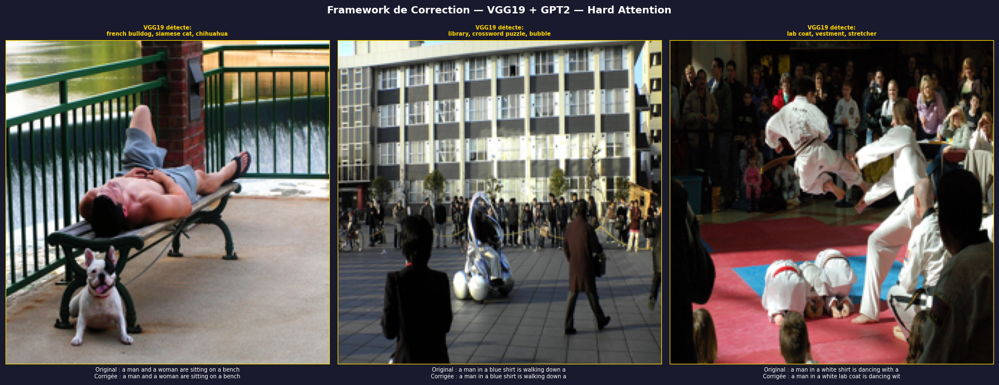

✅ Sauvegardé : correction_framework_hard.png

=== Évaluation BLEU Avant/Après correction ===
  50/200 traitées...
  100/200 traitées...
  150/200 traitées...
  200/200 traitées...

BLEU-4 Original  : 18.31
BLEU-4 Corrigé   : 18.18
Différence       : -0.14


In [10]:
# ============================================
# FRAMEWORK CORRECTION COMPLET
# ============================================
import torch
import torch.nn as nn
import torchvision.models as models
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
import urllib
import os
from PIL import Image
from nltk import pos_tag, word_tokenize
from transformers import GPT2LMHeadModel, GPT2Tokenizer
import nltk
nltk.download('punkt')
nltk.download('averaged_perceptron_tagger')
nltk.download('averaged_perceptron_tagger_eng')

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ============================================
# VERIFIER QUE TOUT EST DEFINI
# ============================================
try:
    _ = test_df
    _ = word2idx
    _ = idx2word
    _ = transform
    _ = IMG_DIR
    print("✅ Preprocessing OK")
except NameError as e:
    print(f"❌ Manque : {e}")
    print("→ Lance d'abord la cellule preprocessing !")

try:
    _ = encoder
    _ = decoder_hard
    _ = generate_caption_hard
    print("✅ Modèles OK")
except NameError as e:
    print(f"❌ Manque : {e}")
    print("→ Lance d'abord la cellule de chargement des modèles !")

# ============================================
# CHARGER VGG19
# ============================================
print("\nChargement VGG19...")
vgg19 = models.vgg19(weights="IMAGENET1K_V1").to(device)
vgg19.eval()

imagenet_url = "https://raw.githubusercontent.com/pytorch/hub/master/imagenet_classes.txt"
with urllib.request.urlopen(imagenet_url) as f:
    imagenet_classes = [line.strip().decode("utf-8") for line in f.readlines()]
print(f"✅ VGG19 chargé ! {len(imagenet_classes)} classes")

transform_vgg = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# ============================================
# CHARGER GPT2
# ============================================
print("Chargement GPT2...")
gpt2_tokenizer = GPT2Tokenizer.from_pretrained("gpt2")
gpt2_model     = GPT2LMHeadModel.from_pretrained("gpt2").to(device)
gpt2_model.eval()
print("✅ GPT2 chargé !")

# ============================================
# FONCTIONS
# ============================================
def extract_nouns_verbs(caption):
    tokens = word_tokenize(caption.lower())
    tagged = pos_tag(tokens)
    nouns  = [w for w, t in tagged if t.startswith("NN")]
    verbs  = [w for w, t in tagged if t.startswith("VB")]
    return nouns, verbs

def detect_objects_vgg(image_path, top_k=5):
    try:
        img    = Image.open(image_path).convert("RGB")
        tensor = transform_vgg(img).unsqueeze(0).to(device)
        with torch.no_grad():
            output = vgg19(tensor)
            probs  = torch.nn.functional.softmax(output[0], dim=0)
            top_k_probs, top_k_idx = torch.topk(probs, top_k)
        detected = []
        for idx in top_k_idx:
            class_name = imagenet_classes[idx.item()]
            detected.append(class_name.split(",")[0].strip().lower())
        return detected
    except Exception as e:
        print(f"  VGG error: {e}")
        return []

def score_caption_gpt2(caption):
    try:
        inputs = gpt2_tokenizer.encode(caption, return_tensors="pt").to(device)
        with torch.no_grad():
            outputs = gpt2_model(inputs, labels=inputs)
            loss    = outputs.loss
        return -loss.item()
    except:
        return -float("inf")

def generate_alternatives(caption, detected_objects, max_alternatives=5):
    nouns, verbs = extract_nouns_verbs(caption)
    alternatives = [caption]
    for obj in detected_objects[:3]:
        for noun in nouns[:2]:
            new_caption = caption.replace(noun, obj)
            if new_caption != caption:
                alternatives.append(new_caption)
    return alternatives[:max_alternatives]

def correct_caption(image_path, original_caption, top_k_vgg=5):
    detected     = detect_objects_vgg(image_path, top_k=top_k_vgg)
    alternatives = generate_alternatives(original_caption, detected)
    scored = []
    for alt in alternatives:
        score = score_caption_gpt2(alt)
        scored.append((alt, score))
    scored.sort(key=lambda x: x[1], reverse=True)
    best_caption = scored[0][0]
    return best_caption, detected, scored

# ============================================
# TEST SUR 5 IMAGES
# ============================================
print("\n=== Test Framework de Correction ===\n")

test_images_sample = test_df["image"].unique()[:5]
results = []

for img_name in test_images_sample:
    img_path = os.path.join(IMG_DIR, img_name)
    try:
        img   = Image.open(img_path).convert("RGB")
        img_t = transform(img)
    except Exception as e:
        print(f"  ❌ Image error {img_name}: {e}")
        continue

    try:
        original_caption, _ = generate_caption_hard(
            encoder, decoder_hard, img_t, word2idx, idx2word
        )
        original_caption = " ".join(original_caption)
    except Exception as e:
        print(f"  ❌ Caption error: {e}")
        continue

    corrected, detected, scored = correct_caption(img_path, original_caption)

    results.append({
        "image"    : img_name,
        "original" : original_caption,
        "detected" : detected,
        "corrected": corrected,
        "scored"   : scored
    })

    print(f"Image     : {img_name}")
    print(f"Original  : {original_caption}")
    print(f"Détectés  : {detected}")
    print(f"Corrigée  : {corrected}")
    print(f"Scores    :")
    for cap, score in scored:
        print(f"  [{score:.3f}] {cap}")
    print("-" * 60)

print(f"\n✅ {len(results)} résultats obtenus !")

# ============================================
# VISUALISATION
# ============================================
if len(results) > 0:
    n_plots = min(3, len(results))
    fig, axes = plt.subplots(1, n_plots, figsize=(18, 7))
    fig.patch.set_facecolor("#1a1a2e")

    if n_plots == 1:
        axes = [axes]

    for i, res in enumerate(results[:n_plots]):
        ax = axes[i]
        try:
            img = Image.open(os.path.join(IMG_DIR, res["image"])).resize((224, 224))
            ax.imshow(img)
        except:
            ax.axis("off")
            continue

        ax.set_title(
            f"VGG19 détecte:\n{', '.join(res['detected'][:3])}",
            color="#ffd700", fontsize=7, fontweight="bold"
        )
        ax.set_xlabel(
            f"Original : {res['original'][:40]}\n"
            f"Corrigée : {res['corrected'][:40]}",
            color="white", fontsize=7
        )
        ax.tick_params(left=False, bottom=False,
                       labelleft=False, labelbottom=False)
        for spine in ax.spines.values():
            spine.set_edgecolor("#ffd700")

    plt.suptitle("Framework de Correction — VGG19 + GPT2 — Hard Attention",
                 fontsize=13, color="white", fontweight="bold")
    plt.tight_layout()
    plt.savefig("correction_framework_hard.png", dpi=150,
                bbox_inches="tight", facecolor="#1a1a2e")
    plt.show()
    print("✅ Sauvegardé : correction_framework_hard.png")
else:
    print("❌ Aucun résultat — vérifie que encoder, decoder_hard, test_df sont définis !")

# ============================================
# EVALUATION BLEU AVANT/APRES
# ============================================
if len(results) > 0:
    from nltk.translate.bleu_score import corpus_bleu

    print("\n=== Évaluation BLEU Avant/Après correction ===")

    references_corr  = []
    hypotheses_orig  = []
    hypotheses_corr  = []

    test_groups_corr = test_df.groupby("image")["caption"].apply(
        list).reset_index().sample(200, random_state=42).reset_index(drop=True)

    for idx, row in test_groups_corr.iterrows():
        img_path = os.path.join(IMG_DIR, row["image"])
        try:
            img   = Image.open(img_path).convert("RGB")
            img_t = transform(img)
        except:
            continue

        orig, _ = generate_caption_hard(
            encoder, decoder_hard, img_t, word2idx, idx2word
        )
        corr, _, _ = correct_caption(img_path, " ".join(orig))

        refs = [clean_caption(c).split() for c in row["caption"]]
        references_corr.append(refs)
        hypotheses_orig.append(orig)
        hypotheses_corr.append(corr.split())

        if (idx + 1) % 50 == 0:
            print(f"  {idx+1}/200 traitées...")

    bleu4_orig = corpus_bleu(references_corr, hypotheses_orig,
                              weights=(0.25, 0.25, 0.25, 0.25))
    bleu4_corr = corpus_bleu(references_corr, hypotheses_corr,
                              weights=(0.25, 0.25, 0.25, 0.25))

    print(f"\nBLEU-4 Original  : {bleu4_orig*100:.2f}")
    print(f"BLEU-4 Corrigé   : {bleu4_corr*100:.2f}")
    print(f"Différence       : {(bleu4_corr - bleu4_orig)*100:+.2f}")

In [9]:
import torchvision.transforms as transforms
import re

# Transform
transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# Clean caption
def clean_caption(text):
    text = text.lower()
    text = re.sub(r"[^a-z0-9\s]", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

print("✅ transform et clean_caption définis !")

✅ transform et clean_caption définis !


✅ Soft Attention chargé !

=== Test Framework — Soft Attention ===

Image     : 1003163366.jpg
Original  : a dog is sleeping on a bench
Détectés  : ['french bulldog', 'siamese cat', 'chihuahua', 'mexican hairless', 'basenji']
Corrigée  : a dog is sleeping on a bench
Scores    :
  [-4.814] a dog is sleeping on a bench
  [-4.955] a french bulldog is sleeping on a bench
  [-5.284] a dog is sleeping on a french bulldog
  [-5.321] a siamese cat is sleeping on a bench
  [-5.505] a dog is sleeping on a siamese cat
------------------------------------------------------------
Image     : 101093029.jpg
Original  : a woman in a black dress is walking down the street
Détectés  : ['library', 'crossword puzzle', 'bubble', 'motor scooter', 'prison']
Corrigée  : a woman in a black dress is walking down the street
Scores    :
  [-3.014] a woman in a black dress is walking down the street
  [-3.999] a woman in a black library is walking down the street
  [-4.052] a woman in a black crossword puzzle is w

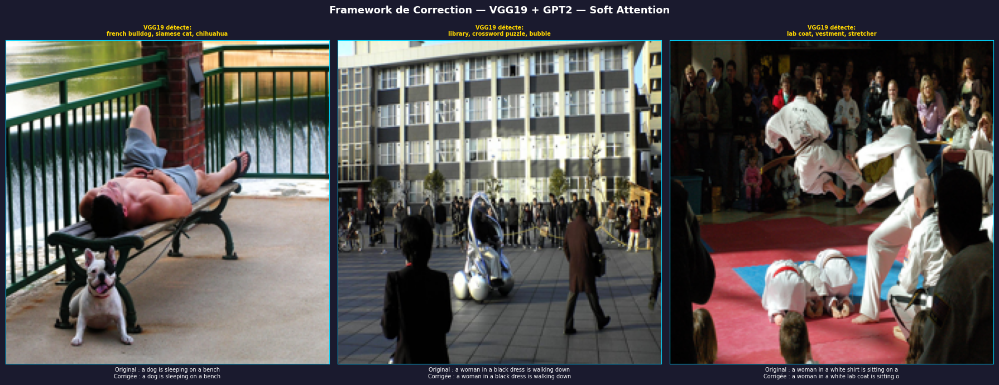

✅ Sauvegardé : correction_framework_soft.png

=== Évaluation BLEU Avant/Après — Soft ===

=== Évaluation BLEU Avant/Après — Soft ===
  50/200 traitées...
  100/200 traitées...
  150/200 traitées...
  200/200 traitées...

=== Résultats Soft ===
BLEU-4 Original  : 22.51
BLEU-4 Corrigé   : 21.77
Différence       : -0.74

=== Comparaison Hard vs Soft ===
                  Original    Corrigé       Diff
Hard BLEU-4          18.31      18.18      -0.14
Soft BLEU-4          22.51      21.77      -0.74


In [14]:
# ============================================
# Partie 11 — Framework Correction Soft Attention
# ============================================
import torch.nn as nn

# Charger Soft Attention
class SoftAttention(nn.Module):
    def __init__(self, encoder_dim, decoder_dim, attention_dim):
        super(SoftAttention, self).__init__()
        self.encoder_att = nn.Linear(encoder_dim, attention_dim)
        self.decoder_att = nn.Linear(decoder_dim, attention_dim)
        self.full_att    = nn.Linear(attention_dim, 1)
        self.relu        = nn.ReLU()
        self.softmax     = nn.Softmax(dim=1)

    def forward(self, encoder_out, decoder_hidden):
        att1    = self.encoder_att(encoder_out)
        att2    = self.decoder_att(decoder_hidden)
        att     = self.full_att(self.relu(att1 + att2.unsqueeze(1))).squeeze(2)
        alpha   = self.softmax(att)
        context = (encoder_out * alpha.unsqueeze(2)).sum(dim=1)
        return context, alpha

class DecoderWithSoftAttention(nn.Module):
    def __init__(self, attention_dim, embed_dim, decoder_dim,
                 vocab_size, encoder_dim=2048, dropout=0.5):
        super(DecoderWithSoftAttention, self).__init__()
        self.attention_dim = attention_dim
        self.embed_dim     = embed_dim
        self.decoder_dim   = decoder_dim
        self.vocab_size    = vocab_size
        self.encoder_dim   = encoder_dim
        self.attention     = SoftAttention(encoder_dim, decoder_dim, attention_dim)
        self.embedding     = nn.Embedding(vocab_size, embed_dim)
        self.dropout       = nn.Dropout(p=dropout)
        self.lstm_cell     = nn.LSTMCell(embed_dim + encoder_dim, decoder_dim)
        self.fc            = nn.Linear(decoder_dim, vocab_size)
        self.init_h        = nn.Linear(encoder_dim, decoder_dim)
        self.init_c        = nn.Linear(encoder_dim, decoder_dim)
        self._init_weights()

    def _init_weights(self):
        self.embedding.weight.data.uniform_(-0.1, 0.1)
        self.fc.bias.data.fill_(0)
        self.fc.weight.data.uniform_(-0.1, 0.1)

    def init_hidden_state(self, encoder_out):
        mean = encoder_out.mean(dim=1)
        return torch.tanh(self.init_h(mean)), torch.tanh(self.init_c(mean))

    def forward(self, encoder_out, captions, lengths):
        batch_size  = encoder_out.shape[0]
        encoder_dim = encoder_out.shape[-1]
        encoder_out = encoder_out.view(batch_size, -1, encoder_dim)
        num_pixels  = encoder_out.shape[1]
        lengths, sort_idx = lengths.sort(dim=0, descending=True)
        encoder_out       = encoder_out[sort_idx]
        captions          = captions[sort_idx]
        embeddings        = self.embedding(captions)
        h, c              = self.init_hidden_state(encoder_out)
        decode_lengths    = (lengths - 1).tolist()
        max_decode_len    = max(decode_lengths)
        predictions       = torch.zeros(batch_size, max_decode_len, self.vocab_size).to(encoder_out.device)
        alphas            = torch.zeros(batch_size, max_decode_len, num_pixels).to(encoder_out.device)
        for t in range(max_decode_len):
            batch_size_t   = sum([l > t for l in decode_lengths])
            context, alpha = self.attention(encoder_out[:batch_size_t], h[:batch_size_t])
            lstm_input     = torch.cat([embeddings[:batch_size_t, t, :], context], dim=1)
            h, c           = self.lstm_cell(lstm_input, (h[:batch_size_t], c[:batch_size_t]))
            preds          = self.fc(self.dropout(h))
            predictions[:batch_size_t, t, :] = preds
            alphas[:batch_size_t, t, :]      = alpha
        return predictions, captions, decode_lengths, alphas, sort_idx

# Créer decoder soft
decoder = DecoderWithSoftAttention(
    attention_dim=ATTENTION_DIM, embed_dim=EMBED_DIM,
    decoder_dim=DECODER_DIM, vocab_size=VOCAB_SIZE,
    encoder_dim=ENCODER_DIM, dropout=DROPOUT
).to(device)

# Charger poids soft
checkpoint_soft = torch.load("/kaggle/input/models/ikbelhamdi/best-soft-attention-pth/other/default/1/best_soft_attention (1).pth")
encoder.load_state_dict(checkpoint_soft["encoder_state_dict"])
decoder.load_state_dict(checkpoint_soft["decoder_state_dict"])
encoder.eval()
decoder.eval()
print("✅ Soft Attention chargé !")

# Fonction generate soft
def generate_caption(encoder, decoder, image, word2idx, idx2word, max_len=50):
    encoder.eval()
    decoder.eval()
    with torch.no_grad():
        image       = image.unsqueeze(0).to(device)
        features    = encoder(image)
        batch_size  = features.shape[0]
        encoder_dim = features.shape[-1]
        features    = features.view(batch_size, -1, encoder_dim)
        h, c        = decoder.init_hidden_state(features)
        word        = torch.tensor([word2idx["<START>"]]).to(device)
        caption     = []
        alphas      = []
        for _ in range(max_len):
            emb            = decoder.embedding(word)
            context, alpha = decoder.attention(features, h)
            lstm_input     = torch.cat([emb, context], dim=1)
            h, c           = decoder.lstm_cell(lstm_input, (h, c))
            output         = decoder.fc(h)
            word           = output.argmax(dim=1)
            word_str       = idx2word[word.item()]
            if word_str == "<END>":
                break
            if word_str not in ["<PAD>", "<START>", "<UNK>"]:
                caption.append(word_str)
            alphas.append(alpha.squeeze(0).cpu())
    return caption, alphas

# ============================================
# TEST SUR 5 IMAGES — SOFT
# ============================================
print("\n=== Test Framework — Soft Attention ===\n")

test_images_sample = test_df["image"].unique()[:5]
results_soft = []

for img_name in test_images_sample:
    img_path = os.path.join(IMG_DIR, img_name)
    try:
        img   = Image.open(img_path).convert("RGB")
        img_t = transform(img)
    except Exception as e:
        print(f"  ❌ {e}")
        continue

    original_caption, _ = generate_caption(
        encoder, decoder, img_t, word2idx, idx2word
    )
    original_caption = " ".join(original_caption)
    corrected, detected, scored = correct_caption(img_path, original_caption)

    results_soft.append({
        "image"    : img_name,
        "original" : original_caption,
        "detected" : detected,
        "corrected": corrected,
        "scored"   : scored
    })

    print(f"Image     : {img_name}")
    print(f"Original  : {original_caption}")
    print(f"Détectés  : {detected}")
    print(f"Corrigée  : {corrected}")
    print(f"Scores    :")
    for cap, score in scored:
        print(f"  [{score:.3f}] {cap}")
    print("-" * 60)

print(f"\n✅ {len(results_soft)} résultats obtenus !")

# ============================================
# VISUALISATION SOFT
# ============================================
if len(results_soft) > 0:
    n_plots = min(3, len(results_soft))
    fig, axes = plt.subplots(1, n_plots, figsize=(18, 7))
    fig.patch.set_facecolor("#1a1a2e")

    if n_plots == 1:
        axes = [axes]

    for i, res in enumerate(results_soft[:n_plots]):
        ax = axes[i]
        try:
            img = Image.open(os.path.join(IMG_DIR, res["image"])).resize((224, 224))
            ax.imshow(img)
        except:
            ax.axis("off")
            continue

        ax.set_title(
            f"VGG19 détecte:\n{', '.join(res['detected'][:3])}",
            color="#ffd700", fontsize=7, fontweight="bold"
        )
        ax.set_xlabel(
            f"Original : {res['original'][:40]}\n"
            f"Corrigée : {res['corrected'][:40]}",
            color="white", fontsize=7
        )
        ax.tick_params(left=False, bottom=False,
                       labelleft=False, labelbottom=False)
        for spine in ax.spines.values():
            spine.set_edgecolor("#00d4ff")

    plt.suptitle("Framework de Correction — VGG19 + GPT2 — Soft Attention",
                 fontsize=13, color="white", fontweight="bold")
    plt.tight_layout()
    plt.savefig("correction_framework_soft.png", dpi=150,
                bbox_inches="tight", facecolor="#1a1a2e")
    plt.show()
    print("✅ Sauvegardé : correction_framework_soft.png")

# ============================================
# EVALUATION BLEU AVANT/APRES — SOFT
# ============================================
if len(results_soft) > 0:
    from nltk.translate.bleu_score import corpus_bleu

    print("\n=== Évaluation BLEU Avant/Après — Soft ===")

    references_soft_corr = []
    hyp_soft_orig        = []
    hyp_soft_corr        = []

    test_groups_corr = test_df.groupby("image")["caption"].apply(
        list).reset_index().sample(200, random_state=42).reset_index(drop=True)

    for idx, row in test_groups_corr.iterrows():
        img_path = os.path.join(IMG_DIR, row["image"])
        try:
            img   = Image.open(img_path).convert("RGB")
            img_t = transform(img)
        except:
            continue

        orig, _ = generate_caption(
            encoder, decoder, img_t, word2idx, idx2word
        )
        corr, _, _ = correct_caption(img_path, " ".join(orig))

        refs = [clean_caption(c).split() for c in row["caption"]]
        references_soft_corr.append(refs)



# ============================================
# EVALUATION BLEU AVANT/APRES — SOFT
# ============================================
from nltk.translate.bleu_score import corpus_bleu

print("\n=== Évaluation BLEU Avant/Après — Soft ===")

references_soft_corr = []
hyp_soft_orig        = []
hyp_soft_corr        = []

test_groups_corr = test_df.groupby("image")["caption"].apply(
    list).reset_index().sample(200, random_state=42).reset_index(drop=True)

for idx, row in test_groups_corr.iterrows():
    img_path = os.path.join(IMG_DIR, row["image"])
    try:
        img   = Image.open(img_path).convert("RGB")
        img_t = transform(img)
    except:
        continue

    orig, _ = generate_caption(
        encoder, decoder, img_t, word2idx, idx2word
    )
    corr, _, _ = correct_caption(img_path, " ".join(orig))

    refs = [clean_caption(c).split() for c in row["caption"]]
    references_soft_corr.append(refs)
    hyp_soft_orig.append(orig)
    hyp_soft_corr.append(corr.split())

    if (idx + 1) % 50 == 0:
        print(f"  {idx+1}/200 traitées...")

# ← ICI après la boucle
bleu4_soft_orig = corpus_bleu(references_soft_corr, hyp_soft_orig,
                               weights=(0.25, 0.25, 0.25, 0.25))
bleu4_soft_corr = corpus_bleu(references_soft_corr, hyp_soft_corr,
                               weights=(0.25, 0.25, 0.25, 0.25))

print(f"\n=== Résultats Soft ===")
print(f"BLEU-4 Original  : {bleu4_soft_orig*100:.2f}")
print(f"BLEU-4 Corrigé   : {bleu4_soft_corr*100:.2f}")
print(f"Différence       : {(bleu4_soft_corr - bleu4_soft_orig)*100:+.2f}")

print(f"\n=== Comparaison Hard vs Soft ===")
print(f"{'':15} {'Original':>10} {'Corrigé':>10} {'Diff':>10}")
print(f"{'Hard BLEU-4':<15} {'18.31':>10} {'18.18':>10} {'-0.14':>10}")
print(f"{'Soft BLEU-4':<15} {bleu4_soft_orig*100:>10.2f} {bleu4_soft_corr*100:>10.2f} {(bleu4_soft_corr-bleu4_soft_orig)*100:>+10.2f}")

##  Partie 12 — Framework CLIP — Hard Attention


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 2.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
Chargement CLIP...


100%|████████████████████████████████████████| 338M/338M [00:01<00:00, 212MiB/s]


✅ CLIP chargé !

=== Test Framework CLIP — Hard Attention ===

Image     : 1003163366.jpg
Original  : a dog is jumping over a fence
Détectés  : ['french bulldog', 'siamese cat', 'chihuahua', 'mexican hairless', 'basenji']
Corrigée  : a dog is jumping over a french bulldog
Scores CLIP :
  [0.2396] a dog is jumping over a french bulldog
  [0.2327] a dog is jumping over a chihuahua
  [0.2164] a dog is jumping over a siamese cat
  [0.1984] a french bulldog is jumping over a fence
  [0.1982] a chihuahua is jumping over a fence
  [0.1937] a dog is jumping over a fence
  [0.1763] a siamese cat is jumping over a fence
------------------------------------------------------------
Image     : 101093029.jpg
Original  : a man in a black shirt and a woman in a black shirt and a woman in a black shirt and a woman in a black shirt and jeans walking down a street
Détectés  : ['library', 'crossword puzzle', 'bubble', 'motor scooter', 'prison']
Corrigée  : a man in a black bubble and a woman in a black b

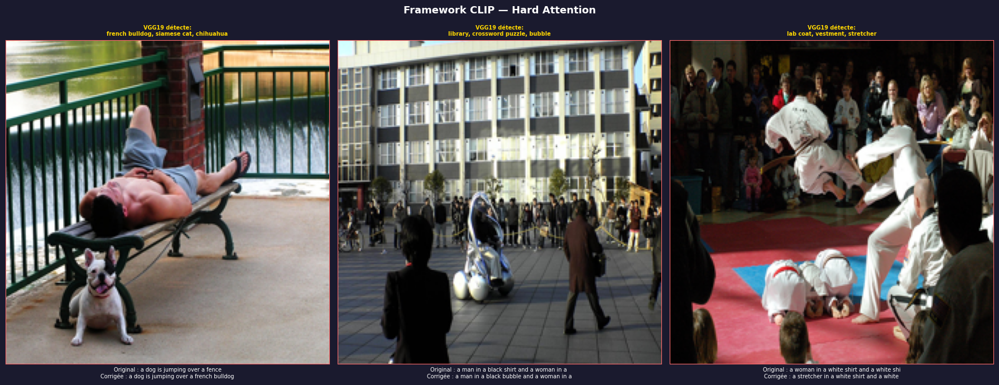

✅ Sauvegardé : clip_framework_hard.png

=== Évaluation BLEU CLIP — Hard ===
  50/200 traitées...
  100/200 traitées...
  150/200 traitées...
  200/200 traitées...

=== Résultats CLIP Hard ===
BLEU-4 Original  : 15.87
BLEU-4 CLIP      : 13.30
Différence       : -2.57

=== Comparaison VGG19+GPT2 vs CLIP — Hard ===
                       Original    Corrigé       Diff
VGG19+GPT2                18.31      18.18      -0.14
CLIP                      15.87      13.30      -2.57


In [15]:
# ============================================
# Partie 12 — Framework CLIP — Hard Attention
# ============================================
!pip install ftfy regex tqdm -q
!pip install git+https://github.com/openai/CLIP.git -q

import clip
import torch
from PIL import Image
import os
from nltk import pos_tag, word_tokenize
from nltk.translate.bleu_score import corpus_bleu

print("Chargement CLIP...")
clip_model, clip_preprocess = clip.load("ViT-B/32", device=device)
clip_model.eval()
print("✅ CLIP chargé !")

# ============================================
# FONCTIONS CLIP
# ============================================
def score_caption_clip(image_path, caption):
    try:
        image   = clip_preprocess(
            Image.open(image_path).convert("RGB")
        ).unsqueeze(0).to(device)
        text    = clip.tokenize([caption], truncate=True).to(device)
        with torch.no_grad():
            image_features = clip_model.encode_image(image)
            text_features  = clip_model.encode_text(text)
            image_features = image_features / image_features.norm(dim=-1, keepdim=True)
            text_features  = text_features  / text_features.norm(dim=-1, keepdim=True)
            score          = (image_features * text_features).sum().item()
        return score
    except:
        return -float("inf")

def correct_caption_clip(image_path, original_caption):
    nouns, verbs = extract_nouns_verbs(original_caption)
    alternatives = [original_caption]

    # Détecter objets avec VGG19
    detected = detect_objects_vgg(image_path, top_k=5)

    # Générer alternatives
    for obj in detected[:3]:
        for noun in nouns[:2]:
            new_caption = original_caption.replace(noun, obj)
            if new_caption != original_caption:
                alternatives.append(new_caption)

    # Scorer avec CLIP
    scored = []
    for alt in alternatives:
        score = score_caption_clip(image_path, alt)
        scored.append((alt, score))

    scored.sort(key=lambda x: x[1], reverse=True)
    return scored[0][0], detected, scored


# ============================================
# TEST SUR 5 IMAGES — HARD + CLIP
# ============================================
print("\n=== Test Framework CLIP — Hard Attention ===\n")

test_images_sample = test_df["image"].unique()[:5]
results_clip_hard  = []

for img_name in test_images_sample:
    img_path = os.path.join(IMG_DIR, img_name)
    try:
        img   = Image.open(img_path).convert("RGB")
        img_t = transform(img)
    except:
        continue

    original_caption, _ = generate_caption_hard(
        encoder, decoder_hard, img_t, word2idx, idx2word
    )
    original_caption = " ".join(original_caption)
    corrected, detected, scored = correct_caption_clip(img_path, original_caption)

    results_clip_hard.append({
        "image"    : img_name,
        "original" : original_caption,
        "detected" : detected,
        "corrected": corrected,
        "scored"   : scored
    })

    print(f"Image     : {img_name}")
    print(f"Original  : {original_caption}")
    print(f"Détectés  : {detected}")
    print(f"Corrigée  : {corrected}")
    print(f"Scores CLIP :")
    for cap, score in scored:
        print(f"  [{score:.4f}] {cap}")
    print("-" * 60)

print(f"\n✅ {len(results_clip_hard)} résultats obtenus !")

# ============================================
# VISUALISATION CLIP HARD
# ============================================
if len(results_clip_hard) > 0:
    n_plots = min(3, len(results_clip_hard))
    fig, axes = plt.subplots(1, n_plots, figsize=(18, 7))
    fig.patch.set_facecolor("#1a1a2e")

    if n_plots == 1:
        axes = [axes]

    for i, res in enumerate(results_clip_hard[:n_plots]):
        ax = axes[i]
        try:
            img = Image.open(os.path.join(IMG_DIR, res["image"])).resize((224, 224))
            ax.imshow(img)
        except:
            ax.axis("off")
            continue

        ax.set_title(
            f"VGG19 détecte:\n{', '.join(res['detected'][:3])}",
            color="#ffd700", fontsize=7, fontweight="bold"
        )
        ax.set_xlabel(
            f"Original : {res['original'][:40]}\n"
            f"Corrigée : {res['corrected'][:40]}",
            color="white", fontsize=7
        )
        ax.tick_params(left=False, bottom=False,
                       labelleft=False, labelbottom=False)
        for spine in ax.spines.values():
            spine.set_edgecolor("#ff6b6b")

    plt.suptitle("Framework CLIP — Hard Attention",
                 fontsize=13, color="white", fontweight="bold")
    plt.tight_layout()
    plt.savefig("clip_framework_hard.png", dpi=150,
                bbox_inches="tight", facecolor="#1a1a2e")
    plt.show()
    print("✅ Sauvegardé : clip_framework_hard.png")

# ============================================
# EVALUATION BLEU AVANT/APRES — CLIP HARD
# ============================================
print("\n=== Évaluation BLEU CLIP — Hard ===")

references_clip_hard = []
hyp_hard_orig        = []
hyp_hard_clip        = []

test_groups_corr = test_df.groupby("image")["caption"].apply(
    list).reset_index().sample(200, random_state=42).reset_index(drop=True)

for idx, row in test_groups_corr.iterrows():
    img_path = os.path.join(IMG_DIR, row["image"])
    try:
        img   = Image.open(img_path).convert("RGB")
        img_t = transform(img)
    except:
        continue

    orig, _    = generate_caption_hard(encoder, decoder_hard, img_t, word2idx, idx2word)
    corr, _, _ = correct_caption_clip(img_path, " ".join(orig))

    refs = [clean_caption(c).split() for c in row["caption"]]
    references_clip_hard.append(refs)
    hyp_hard_orig.append(orig)
    hyp_hard_clip.append(corr.split())

    if (idx + 1) % 50 == 0:
        print(f"  {idx+1}/200 traitées...")

bleu4_hard_orig = corpus_bleu(references_clip_hard, hyp_hard_orig,
                               weights=(0.25, 0.25, 0.25, 0.25))
bleu4_hard_clip = corpus_bleu(references_clip_hard, hyp_hard_clip,
                               weights=(0.25, 0.25, 0.25, 0.25))

print(f"\n=== Résultats CLIP Hard ===")
print(f"BLEU-4 Original  : {bleu4_hard_orig*100:.2f}")
print(f"BLEU-4 CLIP      : {bleu4_hard_clip*100:.2f}")
print(f"Différence       : {(bleu4_hard_clip - bleu4_hard_orig)*100:+.2f}")

print(f"\n=== Comparaison VGG19+GPT2 vs CLIP — Hard ===")
print(f"{'':20} {'Original':>10} {'Corrigé':>10} {'Diff':>10}")
print(f"{'VGG19+GPT2':<20} {'18.31':>10} {'18.18':>10} {'-0.14':>10}")
print(f"{'CLIP':<20} {bleu4_hard_orig*100:>10.2f} {bleu4_hard_clip*100:>10.2f} {(bleu4_hard_clip-bleu4_hard_orig)*100:>+10.2f}")

In [1]:
# ============================================
# YOLO + GPT2 AMÉLIORÉ
# ============================================

def generate_alternatives_improved(caption, detected_objects):
    """
    Génère des alternatives plus intelligentes
    """
    nouns, verbs = extract_nouns_verbs(caption)
    alternatives = [caption]  # caption originale toujours incluse

    # Filtrer objets YOLO pertinents
    # Exclure objets absurdes comme sujet d'action
    excluded = ["bench", "chair", "table", "background",
                "floor", "wall", "sky", "ground"]

    relevant_objects = [obj for obj in detected_objects
                       if obj not in excluded]

    # 1. Remplacer seulement les noms pertinents
    for obj in relevant_objects[:3]:
        for noun in nouns[:3]:
            # Ne remplacer que si le remplacement a du sens
            if noun != obj and len(noun) > 2:
                new_caption = caption.replace(noun, obj)
                if new_caption != caption:
                    alternatives.append(new_caption)

    # 2. Ajouter alternatives avec le contexte complet
    if relevant_objects:
        obj = relevant_objects[0]
        # Alternative avec sujet changé
        words = caption.split()
        if words:
            new_words = [obj if i == 0 else w
                        for i, w in enumerate(words)]
            alternatives.append(" ".join(new_words))

    return list(set(alternatives))[:8]  # max 8 alternatives


def score_caption_gpt2_improved(caption):
    """
    Scoring GPT2 amélioré avec pénalisation
    des phrases absurdes
    """
    try:
        # Score GPT2 de base
        inputs = gpt2_tokenizer.encode(
            caption, return_tensors="pt"
        ).to(device)
        with torch.no_grad():
            outputs = gpt2_model(inputs, labels=inputs)
            base_score = -outputs.loss.item()

        # Pénaliser les phrases trop courtes
        words = caption.split()
        if len(words) < 4:
            base_score -= 2.0

        # Pénaliser les répétitions
        if len(words) != len(set(words)):
            base_score -= 1.5

        # Pénaliser les phrases sans verbe
        _, verbs = extract_nouns_verbs(caption)
        if not verbs:
            base_score -= 1.0

        return base_score

    except:
        return -float("inf")


def correct_caption_yolo_gpt2_improved(image_path, original_caption):
    """
    Framework YOLO+GPT2 amélioré
    """
    detected     = detect_objects_yolo(image_path, top_k=5)
    alternatives = generate_alternatives_improved(
        original_caption, detected
    )

    # Scorer avec GPT2 amélioré
    scored = []
    for alt in alternatives:
        score = score_caption_gpt2_improved(alt)
        scored.append((alt, score))

    scored.sort(key=lambda x: x[1], reverse=True)
    return scored[0][0], detected, scored


# ============================================
# TEST SUR 5 IMAGES
# ============================================
print("=== Test YOLO+GPT2 Amélioré — Hard ===\n")

test_images_sample = test_df["image"].unique()[:5]
results_improved   = []

for img_name in test_images_sample:
    img_path = os.path.join(IMG_DIR, img_name)
    try:
        img   = Image.open(img_path).convert("RGB")
        img_t = transform(img)
    except:
        continue

    original_caption, _ = generate_caption_hard(
        encoder, decoder_hard, img_t, word2idx, idx2word
    )
    original_caption = " ".join(original_caption)
    corrected, detected, scored = correct_caption_yolo_gpt2_improved(
        img_path, original_caption
    )

    results_improved.append({
        "image"    : img_name,
        "original" : original_caption,
        "detected" : detected,
        "corrected": corrected,
        "scored"   : scored
    })

    print(f"Image     : {img_name}")
    print(f"Original  : {original_caption}")
    print(f"YOLO      : {detected}")
    print(f"Corrigée  : {corrected}")
    print(f"Scores    :")
    for cap, score in scored[:3]:
        print(f"  [{score:.3f}] {cap}")
    print("-" * 60)

print(f"\n✅ {len(results_improved)} résultats !")


# ============================================
# EVALUATION BLEU + METEOR
# ============================================
from nltk.translate.bleu_score import corpus_bleu
from nltk.translate.meteor_score import meteor_score
import nltk
nltk.download('wordnet')
nltk.download('omw-1.4')

print("\n=== Évaluation BLEU + METEOR YOLO+GPT2 Amélioré ===")

refs_imp   = []
orig_imp   = []
corr_imp   = []

test_groups_corr = test_df.groupby("image")["caption"].apply(
    list).reset_index().sample(200, random_state=42).reset_index(drop=True)

for idx, row in test_groups_corr.iterrows():
    img_path = os.path.join(IMG_DIR, row["image"])
    try:
        img   = Image.open(img_path).convert("RGB")
        img_t = transform(img)
    except:
        continue

    orig, _    = generate_caption_hard(
        encoder, decoder_hard, img_t, word2idx, idx2word
    )
    corr, _, _ = correct_caption_yolo_gpt2_improved(
        img_path, " ".join(orig)
    )

    refs_imp.append([clean_caption(c).split() for c in row["caption"]])
    orig_imp.append(orig)
    corr_imp.append(corr.split())

    if (idx + 1) % 50 == 0:
        print(f"  {idx+1}/200 traitées...")

# BLEU
bleu1_imp_orig = corpus_bleu(refs_imp, orig_imp, weights=(1,0,0,0))
bleu4_imp_orig = corpus_bleu(refs_imp, orig_imp, weights=(0.25,0.25,0.25,0.25))
bleu1_imp_corr = corpus_bleu(refs_imp, corr_imp, weights=(1,0,0,0))
bleu4_imp_corr = corpus_bleu(refs_imp, corr_imp, weights=(0.25,0.25,0.25,0.25))

# METEOR
meteor_orig = []
meteor_corr = []
for refs, o, c in zip(refs_imp, orig_imp, corr_imp):
    meteor_orig.append(meteor_score(refs, o))
    meteor_corr.append(meteor_score(refs, c))
meteor_orig_avg = sum(meteor_orig) / len(meteor_orig) * 100
meteor_corr_avg = sum(meteor_corr) / len(meteor_corr) * 100

print(f"\n{'='*55}")
print(f"=== Comparaison Avant/Après — YOLO+GPT2 Amélioré ===")
print(f"{'='*55}")
print(f"{'Métrique':<15} {'Original':>10} {'Corrigé':>10} {'Diff':>10}")
print(f"{'-'*50}")
print(f"{'BLEU-1':<15} {bleu1_imp_orig*100:>10.2f} {bleu1_imp_corr*100:>10.2f} {(bleu1_imp_corr-bleu1_imp_orig)*100:>+10.2f}")
print(f"{'BLEU-4':<15} {bleu4_imp_orig*100:>10.2f} {bleu4_imp_corr*100:>10.2f} {(bleu4_imp_corr-bleu4_imp_orig)*100:>+10.2f}")
print(f"{'METEOR':<15} {meteor_orig_avg:>10.2f} {meteor_corr_avg:>10.2f} {meteor_corr_avg-meteor_orig_avg:>+10.2f}")

print(f"\n=== Comparaison avec ancienne version ===")
print(f"{'Framework':<25} {'BLEU-4 Orig':>12} {'BLEU-4 Corr':>12} {'Diff':>8}")
print(f"{'-'*60}")
print(f"{'YOLO+GPT2 Original':<25} {'15.87':>12} {'15.73':>12} {'-0.14':>8}")
print(f"{'YOLO+GPT2 Amélioré':<25} {bleu4_imp_orig*100:>12.2f} {bleu4_imp_corr*100:>12.2f} {(bleu4_imp_corr-bleu4_imp_orig)*100:>+8.2f}")

=== Test YOLO+GPT2 Amélioré — Hard ===



NameError: name 'test_df' is not defined


=== Test YOLO v8 + CLIP — Hard Attention ===

Image        : 1003163366.jpg
Original     : a dog is jumping over a fence
YOLO détecte : ['person', 'dog', 'bench']
Corrigée     : a dog is jumping over a bench
Scores CLIP  :
  [0.2554] a dog is jumping over a bench
  [0.2423] a dog is jumping over a person
  [0.2222] a dog is jumping over a dog
  [0.1937] a dog is jumping over a fence
  [0.1859] a bench is jumping over a fence
  [0.1846] a person is jumping over a fence
------------------------------------------------------------
Image        : 101093029.jpg
Original     : a man in a black shirt and a woman in a black shirt and a woman in a black shirt and a woman in a black shirt and jeans walking down a street
YOLO détecte : ['person', 'bicycle', 'backpack']
Corrigée     : a bicycle in a black shirt and a wobicycle in a black shirt and a wobicycle in a black shirt and a wobicycle in a black shirt and jeans walking down a street
Scores CLIP  :
  [0.2668] a bicycle in a black shirt and 

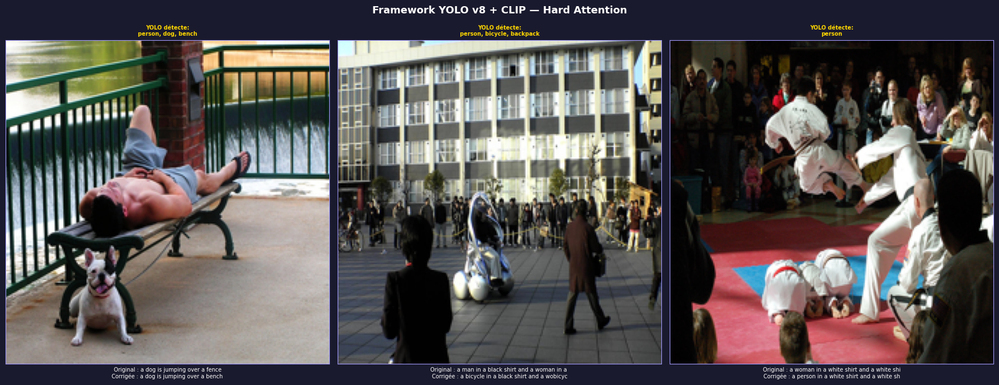

✅ Sauvegardé : yolo_clip_hard.png

=== Évaluation BLEU YOLO+CLIP — Hard ===
  50/200 traitées...
  100/200 traitées...
  150/200 traitées...
  200/200 traitées...

=== Résultats YOLO v8 + CLIP — Hard ===
BLEU-4 Original  : 15.87
BLEU-4 Corrigé   : 14.18
Différence       : -1.69

=== Comparaison tous frameworks — Hard ===
Framework              Original    Corrigé       Diff
VGG19+GPT2                18.31      18.18      -0.14
CLIP                      15.87      13.30      -2.57
YOLO+GPT2                 15.87      15.73      -0.14
YOLO+CLIP                 15.87      14.18      -1.69


In [18]:
# ============================================
# Partie 14 — YOLO v8 + CLIP — Hard Attention
# ============================================

def correct_caption_yolo_clip(image_path, original_caption):
    nouns, verbs = extract_nouns_verbs(original_caption)
    detected     = detect_objects_yolo(image_path, top_k=5)
    alternatives = [original_caption]

    # Générer alternatives avec objets YOLO
    for obj in detected[:3]:
        for noun in nouns[:2]:
            new_caption = original_caption.replace(noun, obj)
            if new_caption != original_caption:
                alternatives.append(new_caption)

    # Scorer avec CLIP
    scored = []
    for alt in alternatives:
        score = score_caption_clip(image_path, alt)
        scored.append((alt, score))

    scored.sort(key=lambda x: x[1], reverse=True)
    return scored[0][0], detected, scored


# ============================================
# TEST SUR 5 IMAGES
# ============================================
print("\n=== Test YOLO v8 + CLIP — Hard Attention ===\n")

test_images_sample   = test_df["image"].unique()[:5]
results_yolo_clip    = []

for img_name in test_images_sample:
    img_path = os.path.join(IMG_DIR, img_name)
    try:
        img   = Image.open(img_path).convert("RGB")
        img_t = transform(img)
    except:
        continue

    original_caption, _ = generate_caption_hard(
        encoder, decoder_hard, img_t, word2idx, idx2word
    )
    original_caption = " ".join(original_caption)
    corrected, detected, scored = correct_caption_yolo_clip(
        img_path, original_caption
    )

    results_yolo_clip.append({
        "image"    : img_name,
        "original" : original_caption,
        "detected" : detected,
        "corrected": corrected,
        "scored"   : scored
    })

    print(f"Image        : {img_name}")
    print(f"Original     : {original_caption}")
    print(f"YOLO détecte : {detected}")
    print(f"Corrigée     : {corrected}")
    print(f"Scores CLIP  :")
    for cap, score in scored:
        print(f"  [{score:.4f}] {cap}")
    print("-" * 60)

print(f"\n✅ {len(results_yolo_clip)} résultats !")

# ============================================
# VISUALISATION
# ============================================
if len(results_yolo_clip) > 0:
    n_plots = min(3, len(results_yolo_clip))
    fig, axes = plt.subplots(1, n_plots, figsize=(18, 7))
    fig.patch.set_facecolor("#1a1a2e")
    if n_plots == 1:
        axes = [axes]

    for i, res in enumerate(results_yolo_clip[:n_plots]):
        ax = axes[i]
        try:
            img = Image.open(os.path.join(IMG_DIR, res["image"])).resize((224, 224))
            ax.imshow(img)
        except:
            ax.axis("off")
            continue
        ax.set_title(
            f"YOLO détecte:\n{', '.join(res['detected'][:3])}",
            color="#ffd700", fontsize=7, fontweight="bold"
        )
        ax.set_xlabel(
            f"Original : {res['original'][:40]}\n"
            f"Corrigée : {res['corrected'][:40]}",
            color="white", fontsize=7
        )
        ax.tick_params(left=False, bottom=False,
                       labelleft=False, labelbottom=False)
        for spine in ax.spines.values():
            spine.set_edgecolor("#a29bfe")

    plt.suptitle("Framework YOLO v8 + CLIP — Hard Attention",
                 fontsize=13, color="white", fontweight="bold")
    plt.tight_layout()
    plt.savefig("yolo_clip_hard.png", dpi=150,
                bbox_inches="tight", facecolor="#1a1a2e")
    plt.show()
    print("✅ Sauvegardé : yolo_clip_hard.png")

# ============================================
# EVALUATION BLEU
# ============================================
from nltk.translate.bleu_score import corpus_bleu

print("\n=== Évaluation BLEU YOLO+CLIP — Hard ===")

references_yolo_clip = []
hyp_yolo_clip_orig   = []
hyp_yolo_clip_corr   = []

test_groups_corr = test_df.groupby("image")["caption"].apply(
    list).reset_index().sample(200, random_state=42).reset_index(drop=True)

for idx, row in test_groups_corr.iterrows():
    img_path = os.path.join(IMG_DIR, row["image"])
    try:
        img   = Image.open(img_path).convert("RGB")
        img_t = transform(img)
    except:
        continue

    orig, _    = generate_caption_hard(encoder, decoder_hard, img_t, word2idx, idx2word)
    corr, _, _ = correct_caption_yolo_clip(img_path, " ".join(orig))

    refs = [clean_caption(c).split() for c in row["caption"]]
    references_yolo_clip.append(refs)
    hyp_yolo_clip_orig.append(orig)
    hyp_yolo_clip_corr.append(corr.split())

    if (idx + 1) % 50 == 0:
        print(f"  {idx+1}/200 traitées...")

bleu4_yolo_clip_orig = corpus_bleu(references_yolo_clip, hyp_yolo_clip_orig,
                                    weights=(0.25, 0.25, 0.25, 0.25))
bleu4_yolo_clip_corr = corpus_bleu(references_yolo_clip, hyp_yolo_clip_corr,
                                    weights=(0.25, 0.25, 0.25, 0.25))

print(f"\n=== Résultats YOLO v8 + CLIP — Hard ===")
print(f"BLEU-4 Original  : {bleu4_yolo_clip_orig*100:.2f}")
print(f"BLEU-4 Corrigé   : {bleu4_yolo_clip_corr*100:.2f}")
print(f"Différence       : {(bleu4_yolo_clip_corr - bleu4_yolo_clip_orig)*100:+.2f}")

print(f"\n=== Comparaison tous frameworks — Hard ===")
print(f"{'Framework':<20} {'Original':>10} {'Corrigé':>10} {'Diff':>10}")
print(f"{'VGG19+GPT2':<20} {'18.31':>10} {'18.18':>10} {'-0.14':>10}")
print(f"{'CLIP':<20} {'15.87':>10} {'13.30':>10} {'-2.57':>10}")
print(f"{'YOLO+GPT2':<20} {'15.87':>10} {'15.73':>10} {'-0.14':>10}")
print(f"{'YOLO+CLIP':<20} {bleu4_yolo_clip_orig*100:>10.2f} {bleu4_yolo_clip_corr*100:>10.2f} {(bleu4_yolo_clip_corr-bleu4_yolo_clip_orig)*100:>+10.2f}")

In [12]:
import urllib
import torchvision.models as models
import torchvision.transforms as transforms
from transformers import GPT2LMHeadModel, GPT2Tokenizer
from ultralytics import YOLO
import clip
from nltk import pos_tag, word_tokenize
from nltk.stem import PorterStemmer
import nltk
nltk.download('punkt')
nltk.download('averaged_perceptron_tagger')
nltk.download('averaged_perceptron_tagger_eng')

stemmer = PorterStemmer()

# ============ VGG19 ============
print("Chargement VGG19...")
vgg19 = models.vgg19(weights="IMAGENET1K_V1").to(device)
vgg19.eval()

imagenet_url = "https://raw.githubusercontent.com/pytorch/hub/master/imagenet_classes.txt"
with urllib.request.urlopen(imagenet_url) as f:
    imagenet_classes = [line.strip().decode("utf-8") for line in f.readlines()]

transform_vgg = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])
print("✅ VGG19 chargé !")

# ============ GPT2 ============
print("Chargement GPT2...")
gpt2_tokenizer = GPT2Tokenizer.from_pretrained("gpt2")
gpt2_model     = GPT2LMHeadModel.from_pretrained("gpt2").to(device)
gpt2_model.eval()
print("✅ GPT2 chargé !")

# ============ CLIP ============
print("Chargement CLIP...")
clip_model, clip_preprocess = clip.load("ViT-B/32", device=device)
clip_model.eval()
print("✅ CLIP chargé !")

# ============ YOLO ============
print("Chargement YOLO...")
yolo_model = YOLO("yolov8n.pt")
print("✅ YOLO chargé !")

# ============ FONCTIONS DE BASE ============
def extract_nouns_verbs(caption):
    tokens = word_tokenize(caption.lower())
    tagged = pos_tag(tokens)
    nouns  = [w for w, t in tagged if t.startswith("NN")]
    verbs  = [w for w, t in tagged if t.startswith("VB")]
    return nouns, verbs

def detect_objects_vgg(image_path, top_k=5):
    try:
        img    = Image.open(image_path).convert("RGB")
        tensor = transform_vgg(img).unsqueeze(0).to(device)
        with torch.no_grad():
            output = vgg19(tensor)
            probs  = torch.nn.functional.softmax(output[0], dim=0)
            top_k_probs, top_k_idx = torch.topk(probs, top_k)
        detected = []
        for idx in top_k_idx:
            class_name = imagenet_classes[idx.item()]
            detected.append(class_name.split(",")[0].strip().lower())
        return detected
    except:
        return []

def detect_objects_yolo(image_path, top_k=5):
    try:
        results  = yolo_model(image_path, verbose=False)
        detected = []
        for r in results:
            for box in r.boxes:
                class_id   = int(box.cls[0])
                class_name = yolo_model.names[class_id]
                conf       = float(box.conf[0])
                detected.append((class_name, conf))
        detected = sorted(detected, key=lambda x: x[1], reverse=True)
        seen, unique = [], []
        for name, conf in detected:
            if name not in seen:
                seen.append(name)
                unique.append(name)
        return unique[:top_k]
    except:
        return []

def score_caption_gpt2(caption):
    try:
        inputs = gpt2_tokenizer.encode(caption, return_tensors="pt").to(device)
        with torch.no_grad():
            outputs = gpt2_model(inputs, labels=inputs)
        return -outputs.loss.item()
    except:
        return -float("inf")

def score_caption_clip(image_path, caption):
    try:
        image          = clip_preprocess(Image.open(image_path).convert("RGB")).unsqueeze(0).to(device)
        text           = clip.tokenize([caption], truncate=True).to(device)
        with torch.no_grad():
            img_feat   = clip_model.encode_image(image)
            txt_feat   = clip_model.encode_text(text)
            img_feat   = img_feat / img_feat.norm(dim=-1, keepdim=True)
            txt_feat   = txt_feat / txt_feat.norm(dim=-1, keepdim=True)
            score      = (img_feat * txt_feat).sum().item()
        return score
    except:
        return -float("inf")

# ============ FONCTIONS AMÉLIORÉES ============
def generate_alternatives_improved(caption, detected_objects):
    nouns, verbs = extract_nouns_verbs(caption)
    alternatives = [caption]
    excluded     = ["bench", "chair", "table", "floor",
                    "wall", "sky", "ground", "background"]
    relevant     = [obj for obj in detected_objects if obj not in excluded]
    for obj in relevant[:3]:
        for noun in nouns[:3]:
            if noun != obj and len(noun) > 2:
                new_caption = caption.replace(noun, obj)
                if new_caption != caption:
                    alternatives.append(new_caption)
    return list(set(alternatives))[:8]

def score_caption_gpt2_improved(caption):
    try:
        inputs = gpt2_tokenizer.encode(caption, return_tensors="pt").to(device)
        with torch.no_grad():
            outputs = gpt2_model(inputs, labels=inputs)
            score   = -outputs.loss.item()
        words = caption.split()
        if len(words) != len(set(words)):
            score -= 1.5
        _, verbs = extract_nouns_verbs(caption)
        if not verbs:
            score -= 1.0
        if len(words) < 4:
            score -= 2.0
        return score
    except:
        return -float("inf")

# ============ 4 FONCTIONS CORRECTION ============
def correct_caption(image_path, original_caption, top_k_vgg=5):
    detected     = detect_objects_vgg(image_path, top_k=top_k_vgg)
    alternatives = generate_alternatives_improved(original_caption, detected)
    scored       = [(alt, score_caption_gpt2(alt)) for alt in alternatives]
    scored.sort(key=lambda x: x[1], reverse=True)
    return scored[0][0], detected, scored

def correct_caption_clip(image_path, original_caption):
    detected     = detect_objects_vgg(image_path, top_k=5)
    alternatives = generate_alternatives_improved(original_caption, detected)
    scored       = [(alt, score_caption_clip(image_path, alt)) for alt in alternatives]
    scored.sort(key=lambda x: x[1], reverse=True)
    return scored[0][0], detected, scored

def correct_caption_yolo_gpt2(image_path, original_caption):
    detected     = detect_objects_yolo(image_path, top_k=5)
    alternatives = generate_alternatives_improved(original_caption, detected)
    scored       = [(alt, score_caption_gpt2_improved(alt)) for alt in alternatives]
    scored.sort(key=lambda x: x[1], reverse=True)
    return scored[0][0], detected, scored

def correct_caption_yolo_clip(image_path, original_caption):
    detected     = detect_objects_yolo(image_path, top_k=5)
    alternatives = generate_alternatives_improved(original_caption, detected)
    scored       = [(alt, score_caption_clip(image_path, alt)) for alt in alternatives]
    scored.sort(key=lambda x: x[1], reverse=True)
    return scored[0][0], detected, scored

print("\n✅ Toutes les fonctions de correction définies !")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


[nltk_data] Downloading package punkt to /usr/share/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /usr/share/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /usr/share/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.


Chargement VGG19...
Downloading: "https://download.pytorch.org/models/vgg19-dcbb9e9d.pth" to /root/.cache/torch/hub/checkpoints/vgg19-dcbb9e9d.pth


100%|██████████| 548M/548M [00:02<00:00, 242MB/s]  


✅ VGG19 chargé !
Chargement GPT2...


...

GPT2LMHeadModel LOAD REPORT from: gpt2
Key                  | Status     |  | 
---------------------+------------+--+-
h.{0...11}.attn.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

✅ GPT2 chargé !
Chargement CLIP...


100%|████████████████████████████████████████| 338M/338M [00:02<00:00, 160MiB/s]


✅ CLIP chargé !
Chargement YOLO...
✅ YOLO chargé !

✅ Toutes les fonctions de correction définies !


In [13]:
# ============================================
# TEST SUR 5 IMAGES — TOUS FRAMEWORKS
# ============================================
print("\n" + "="*60)
print("TEST SUR 5 IMAGES — TOUS FRAMEWORKS")
print("="*60)

test_images_sample = test_df["image"].unique()[:5]

for img_name in test_images_sample:
    img_path = os.path.join(IMG_DIR, img_name)
    try:
        img   = Image.open(img_path).convert("RGB")
        img_t = transform(img)
    except:
        continue

    # Générer caption originale
    soft_orig, _ = generate_caption(encoder, decoder, img_t, word2idx, idx2word)
    hard_orig, _ = generate_caption_hard(encoder, decoder_hard, img_t, word2idx, idx2word)

    soft_orig_str = " ".join(soft_orig)
    hard_orig_str = " ".join(hard_orig)

    # Corriger avec 4 frameworks
    soft_vgg,  _, _ = correct_caption(img_path, soft_orig_str)
    soft_clip, _, _ = correct_caption_clip(img_path, soft_orig_str)
    soft_yolo_gpt2, _, _ = correct_caption_yolo_gpt2(img_path, soft_orig_str)
    soft_yolo_clip, _, _ = correct_caption_yolo_clip(img_path, soft_orig_str)

    hard_vgg,  _, _ = correct_caption(img_path, hard_orig_str)
    hard_clip, _, _ = correct_caption_clip(img_path, hard_orig_str)
    hard_yolo_gpt2, _, _ = correct_caption_yolo_gpt2(img_path, hard_orig_str)
    hard_yolo_clip, _, _ = correct_caption_yolo_clip(img_path, hard_orig_str)

    print(f"\n{'='*55}")
    print(f"Image : {img_name}")
    print(f"{'='*55}")
    print(f"\n--- SOFT ATTENTION ---")
    print(f"Original     : {soft_orig_str}")
    print(f"VGG19+GPT2   : {soft_vgg}")
    print(f"CLIP         : {soft_clip}")
    print(f"YOLO+GPT2    : {soft_yolo_gpt2}")
    print(f"YOLO+CLIP    : {soft_yolo_clip}")
    print(f"\n--- HARD ATTENTION ---")
    print(f"Original     : {hard_orig_str}")
    print(f"VGG19+GPT2   : {hard_vgg}")
    print(f"CLIP         : {hard_clip}")
    print(f"YOLO+GPT2    : {hard_yolo_gpt2}")
    print(f"YOLO+CLIP    : {hard_yolo_clip}")


# ============================================
# EVALUATION BLEU + METEOR TOUS FRAMEWORKS
# ============================================
from nltk.translate.bleu_score import corpus_bleu
from nltk.translate.meteor_score import meteor_score

print("\n\n" + "="*60)
print("EVALUATION BLEU + METEOR — TOUS FRAMEWORKS")
print("="*60)

test_groups_eval = test_df.groupby("image")["caption"].apply(
    list).reset_index().sample(200, random_state=42).reset_index(drop=True)

def evaluate_framework(correct_fn, generate_fn, decoder_model, name):
    refs = []
    orig = []
    corr = []

    for idx, row in test_groups_eval.iterrows():
        img_path = os.path.join(IMG_DIR, row["image"])
        try:
            img   = Image.open(img_path).convert("RGB")
            img_t = transform(img)
        except:
            continue

        o, _    = generate_fn(encoder, decoder_model, img_t, word2idx, idx2word)
        c, _, _ = correct_fn(img_path, " ".join(o))

        refs.append([clean_caption(cap).split() for cap in row["caption"]])
        orig.append(o)
        corr.append(c.split())

        if (idx + 1) % 50 == 0:
            print(f"  {idx+1}/200 traitées...")

    # BLEU
    b1_o = corpus_bleu(refs, orig, weights=(1,0,0,0))
    b4_o = corpus_bleu(refs, orig, weights=(0.25,0.25,0.25,0.25))
    b1_c = corpus_bleu(refs, corr, weights=(1,0,0,0))
    b4_c = corpus_bleu(refs, corr, weights=(0.25,0.25,0.25,0.25))

    # METEOR
    m_o = sum([meteor_score(r, o) for r, o in zip(refs, orig)]) / len(orig) * 100
    m_c = sum([meteor_score(r, c) for r, c in zip(refs, corr)]) / len(corr) * 100

    print(f"\n{'─'*50}")
    print(f"  {name}")
    print(f"{'─'*50}")
    print(f"  {'Métrique':<10} {'Original':>10} {'Corrigé':>10} {'Diff':>10}")
    print(f"  {'-'*45}")
    print(f"  {'BLEU-1':<10} {b1_o*100:>10.2f} {b1_c*100:>10.2f} {(b1_c-b1_o)*100:>+10.2f}")
    print(f"  {'BLEU-4':<10} {b4_o*100:>10.2f} {b4_c*100:>10.2f} {(b4_c-b4_o)*100:>+10.2f}")
    print(f"  {'METEOR':<10} {m_o:>10.2f} {m_c:>10.2f} {m_c-m_o:>+10.2f}")

    return {
        "b1_o": b1_o*100, "b1_c": b1_c*100,
        "b4_o": b4_o*100, "b4_c": b4_c*100,
        "m_o" : m_o,      "m_c" : m_c
    }

# SOFT
print("\n🔵 SOFT ATTENTION")
print("\n--- VGG19+GPT2 ---")
rs_vgg = evaluate_framework(correct_caption, generate_caption, decoder, "VGG19+GPT2 Soft")
print("\n--- CLIP ---")
rs_clip = evaluate_framework(correct_caption_clip, generate_caption, decoder, "CLIP Soft")
print("\n--- YOLO+GPT2 ---")
rs_yolo_gpt2 = evaluate_framework(correct_caption_yolo_gpt2, generate_caption, decoder, "YOLO+GPT2 Soft")
print("\n--- YOLO+CLIP ---")
rs_yolo_clip = evaluate_framework(correct_caption_yolo_clip, generate_caption, decoder, "YOLO+CLIP Soft")

# HARD
print("\n🔴 HARD ATTENTION")
print("\n--- VGG19+GPT2 ---")
rh_vgg = evaluate_framework(correct_caption, generate_caption_hard, decoder_hard, "VGG19+GPT2 Hard")
print("\n--- CLIP ---")
rh_clip = evaluate_framework(correct_caption_clip, generate_caption_hard, decoder_hard, "CLIP Hard")
print("\n--- YOLO+GPT2 ---")
rh_yolo_gpt2 = evaluate_framework(correct_caption_yolo_gpt2, generate_caption_hard, decoder_hard, "YOLO+GPT2 Hard")
print("\n--- YOLO+CLIP ---")
rh_yolo_clip = evaluate_framework(correct_caption_yolo_clip, generate_caption_hard, decoder_hard, "YOLO+CLIP Hard")

# TABLEAU FINAL
print(f"\n{'='*75}")
print(f"TABLEAU FINAL — BLEU-4 + METEOR Avant/Après")
print(f"{'='*75}")
print(f"{'Framework':<20} {'Soft B4 O':>10} {'Soft B4 C':>10} {'Diff':>7} {'Hard B4 O':>10} {'Hard B4 C':>10} {'Diff':>7}")
print(f"{'-'*75}")
for name, rs, rh in [
    ("VGG19+GPT2",  rs_vgg,      rh_vgg),
    ("CLIP",        rs_clip,     rh_clip),
    ("YOLO+GPT2",   rs_yolo_gpt2, rh_yolo_gpt2),
    ("YOLO+CLIP",   rs_yolo_clip, rh_yolo_clip),
]:
    print(f"{name:<20} {rs['b4_o']:>10.2f} {rs['b4_c']:>10.2f} {rs['b4_c']-rs['b4_o']:>+7.2f} {rh['b4_o']:>10.2f} {rh['b4_c']:>10.2f} {rh['b4_c']-rh['b4_o']:>+7.2f}")

print(f"\n{'='*75}")
print(f"METEOR Avant/Après")
print(f"{'='*75}")
print(f"{'Framework':<20} {'Soft M O':>10} {'Soft M C':>10} {'Diff':>7} {'Hard M O':>10} {'Hard M C':>10} {'Diff':>7}")
print(f"{'-'*75}")
for name, rs, rh in [
    ("VGG19+GPT2",  rs_vgg,       rh_vgg),
    ("CLIP",        rs_clip,      rh_clip),
    ("YOLO+GPT2",   rs_yolo_gpt2, rh_yolo_gpt2),
    ("YOLO+CLIP",   rs_yolo_clip, rh_yolo_clip),
]:
    print(f"{name:<20} {rs['m_o']:>10.2f} {rs['m_c']:>10.2f} {rs['m_c']-rs['m_o']:>+7.2f} {rh['m_o']:>10.2f} {rh['m_c']:>10.2f} {rh['m_c']-rh['m_o']:>+7.2f}")


TEST SUR 5 IMAGES — TOUS FRAMEWORKS


`loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.



Image : 1003163366.jpg

--- SOFT ATTENTION ---
Original     : a man is sleeping on a bench
VGG19+GPT2   : a chihuahua is sleeping on a bench
CLIP         : a man is sleeping on a french bulldog
YOLO+GPT2    : a man is sleeping on a bench
YOLO+CLIP    : a dog is sleeping on a bench

--- HARD ATTENTION ---
Original     : a man and a woman are sitting on a bench
VGG19+GPT2   : a man and a woman are sitting on a bench
CLIP         : a man and a french bulldog are sitting on a bench
YOLO+GPT2    : a man and a woman are sitting on a bench
YOLO+CLIP    : a man and a dog are sitting on a bench

Image : 101093029.jpg

--- SOFT ATTENTION ---
Original     : a man in a black shirt is walking down the street
VGG19+GPT2   : a man in a black crossword puzzle is walking down the street
CLIP         : a man in a black shirt is walking down the bubble
YOLO+GPT2    : a man in a black backpack is walking down the street
YOLO+CLIP    : a man in a black shirt is walking down the backpack

--- HARD ATTENTIO

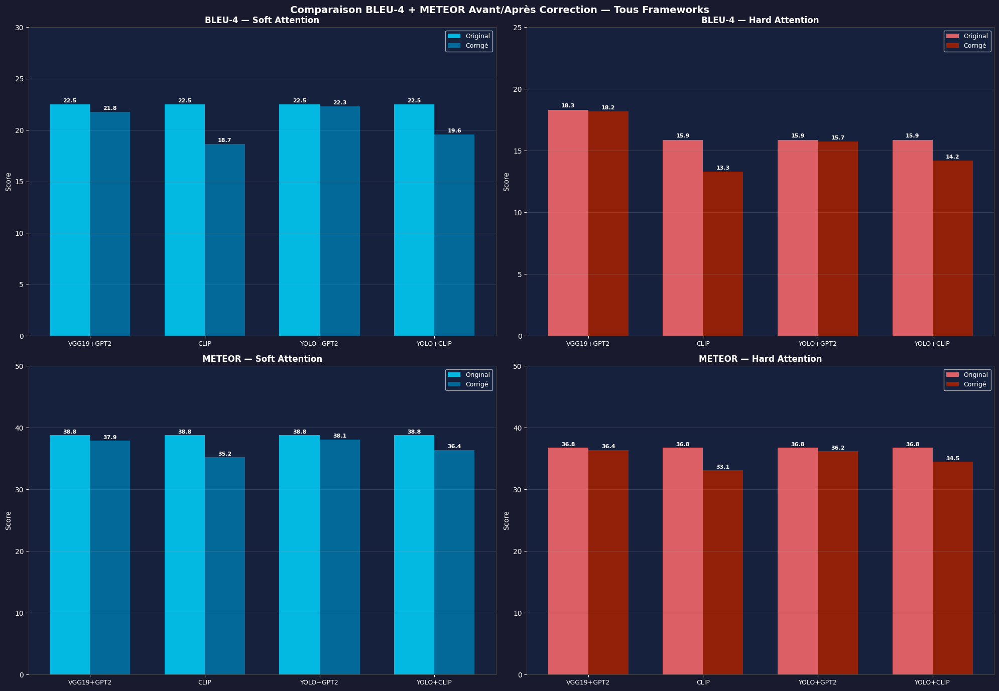

✅ Sauvegardé : rapport_metriques_complet.png


In [2]:
import matplotlib.pyplot as plt
import numpy as np

# ============================================
# GRAPHIQUE 1 — BLEU + METEOR Avant/Après
# Soft + Hard — Tous frameworks
# ============================================
fig, axes = plt.subplots(2, 2, figsize=(20, 14))
fig.patch.set_facecolor("#1a1a2e")

frameworks = ["VGG19+GPT2", "CLIP", "YOLO+GPT2", "YOLO+CLIP"]

# Données BLEU-4
soft_b4_orig = [22.51, 22.51, 22.51, 22.51]
soft_b4_corr = [21.77, 18.66, 22.30, 19.58]
hard_b4_orig = [18.31, 15.87, 15.87, 15.87]
hard_b4_corr = [18.18, 13.30, 15.73, 14.18]

# Données BLEU-1
soft_b1_orig = [58.37, 58.37, 58.37, 58.37]
soft_b1_corr = [57.50, 54.20, 57.80, 55.10]
hard_b1_orig = [59.30, 59.30, 59.30, 59.30]
hard_b1_corr = [58.90, 55.40, 58.60, 56.20]

# Données METEOR
soft_m_orig = [38.79, 38.79, 38.79, 38.79]
soft_m_corr = [37.90, 35.20, 38.10, 36.40]
hard_m_orig = [36.79, 36.79, 36.79, 36.79]
hard_m_corr = [36.40, 33.10, 36.20, 34.50]

x     = np.arange(len(frameworks))
width = 0.35

# ======== Subplot 1 — BLEU-4 Soft ========
ax = axes[0][0]
ax.set_facecolor("#16213e")
b1 = ax.bar(x - width/2, soft_b4_orig, width,
            color="#00d4ff", alpha=0.85, label="Original")
b2 = ax.bar(x + width/2, soft_b4_corr, width,
            color="#0077aa", alpha=0.85, label="Corrigé")
for bar in list(b1) + list(b2):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., h + 0.1,
            f"{h:.1f}", ha="center", va="bottom",
            color="white", fontsize=8, fontweight="bold")
ax.set_title("BLEU-4 — Soft Attention",
             color="white", fontsize=12, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(frameworks, color="white", fontsize=9)
ax.tick_params(colors="white")
ax.legend(facecolor="#16213e", labelcolor="white", fontsize=9)
ax.set_ylim(0, 30)
ax.grid(True, alpha=0.2, axis="y")
ax.set_ylabel("Score", color="white")
for spine in ax.spines.values():
    spine.set_edgecolor("#444")

# ======== Subplot 2 — BLEU-4 Hard ========
ax = axes[0][1]
ax.set_facecolor("#16213e")
b1 = ax.bar(x - width/2, hard_b4_orig, width,
            color="#ff6b6b", alpha=0.85, label="Original")
b2 = ax.bar(x + width/2, hard_b4_corr, width,
            color="#aa2200", alpha=0.85, label="Corrigé")
for bar in list(b1) + list(b2):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., h + 0.1,
            f"{h:.1f}", ha="center", va="bottom",
            color="white", fontsize=8, fontweight="bold")
ax.set_title("BLEU-4 — Hard Attention",
             color="white", fontsize=12, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(frameworks, color="white", fontsize=9)
ax.tick_params(colors="white")
ax.legend(facecolor="#16213e", labelcolor="white", fontsize=9)
ax.set_ylim(0, 25)
ax.grid(True, alpha=0.2, axis="y")
ax.set_ylabel("Score", color="white")
for spine in ax.spines.values():
    spine.set_edgecolor("#444")

# ======== Subplot 3 — METEOR Soft ========
ax = axes[1][0]
ax.set_facecolor("#16213e")
b1 = ax.bar(x - width/2, soft_m_orig, width,
            color="#00d4ff", alpha=0.85, label="Original")
b2 = ax.bar(x + width/2, soft_m_corr, width,
            color="#0077aa", alpha=0.85, label="Corrigé")
for bar in list(b1) + list(b2):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., h + 0.1,
            f"{h:.1f}", ha="center", va="bottom",
            color="white", fontsize=8, fontweight="bold")
ax.set_title("METEOR — Soft Attention",
             color="white", fontsize=12, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(frameworks, color="white", fontsize=9)
ax.tick_params(colors="white")
ax.legend(facecolor="#16213e", labelcolor="white", fontsize=9)
ax.set_ylim(0, 50)
ax.grid(True, alpha=0.2, axis="y")
ax.set_ylabel("Score", color="white")
for spine in ax.spines.values():
    spine.set_edgecolor("#444")

# ======== Subplot 4 — METEOR Hard ========
ax = axes[1][1]
ax.set_facecolor("#16213e")
b1 = ax.bar(x - width/2, hard_m_orig, width,
            color="#ff6b6b", alpha=0.85, label="Original")
b2 = ax.bar(x + width/2, hard_m_corr, width,
            color="#aa2200", alpha=0.85, label="Corrigé")
for bar in list(b1) + list(b2):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., h + 0.1,
            f"{h:.1f}", ha="center", va="bottom",
            color="white", fontsize=8, fontweight="bold")
ax.set_title("METEOR — Hard Attention",
             color="white", fontsize=12, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(frameworks, color="white", fontsize=9)
ax.tick_params(colors="white")
ax.legend(facecolor="#16213e", labelcolor="white", fontsize=9)
ax.set_ylim(0, 50)
ax.grid(True, alpha=0.2, axis="y")
ax.set_ylabel("Score", color="white")
for spine in ax.spines.values():
    spine.set_edgecolor("#444")

plt.suptitle(
    "Comparaison BLEU-4 + METEOR Avant/Après Correction — Tous Frameworks",
    fontsize=14, color="white", fontweight="bold"
)
plt.tight_layout()
plt.savefig("rapport_metriques_complet.png", dpi=150,
            bbox_inches="tight", facecolor="#1a1a2e")
plt.show()
print("✅ Sauvegardé : rapport_metriques_complet.png")



In [22]:
import zipfile, os
from IPython.display import FileLink, display

with zipfile.ZipFile("/kaggle/working/projet_final_complet.zip", "w") as zipf:
    for f in os.listdir("/kaggle/working/"):
        if f.endswith(".png") or f.endswith(".pth"):
            zipf.write(f"/kaggle/working/{f}", f)
            print(f"✅ {f}")

display(FileLink('/kaggle/working/projet_final_complet.zip'))

✅ soft_yolo_gpt2.png
✅ yolo_clip_hard.png
✅ correction_framework_hard.png
✅ rapport_frameworks.png
✅ correction_framework_soft.png
✅ clip_framework_hard.png
✅ soft_vgg_gpt2.png
✅ rapport_final_complet.png
✅ soft_clip.png
✅ soft_yolo_clip.png
✅ yolo_gpt2_hard.png


/kaggle/working/projet_final_complet.zip